# Small-Signal Stability of a Converter-Dominated Grid with PowerDynamics.jl and SciML

Companion tutorial to the talk *"Small-Signal Analysis using Automatic Differentiation in the Open-Source
Software PowerDynamics.jl"* (S. Eberlein, H. Würfel, L. Bittcher), special session *Small-Signal Analysis of Modern
Power Systems: Novel Approaches and Computational Tools*, IEEE ISGT Europe 2026, Budapest.

**One nonlinear model, many small-signal analyses.** All results below come from a single nonlinear quasi-EMT model (dq frame) of a
modified IEEE 9-bus system. Every linear model, sensitivity and gradient is obtained by **automatic
differentiation (AD)** of that model — no hand-derived small-signal equations, no finite-difference step sizes.

| Analysis | Julia / SciML packages |
|---|---|
| Modelling, power flow, initialization, time domain | PowerDynamics.jl, NetworkDynamics.jl, ModelingToolkit.jl, OrdinaryDiffEq.jl |
| Linearization ($\mathbf A, \mathbf B, \mathbf C, \mathbf D$), eigenvalues, participation factors | NetworkDynamics.jl + ForwardDiff.jl |
| Eigenvalue sensitivities $\partial\lambda/\partial p$ | NetworkDynamics.jl, nested ForwardDiff.jl |
| Eigenvalue tracking, stability boundary | BifurcationKit.jl, KrylovKit.jl |
| Impedances, generalized Nyquist | NetworkDynamics.jl (`open_loop_linearization`), ControlSystemsBase.jl |
| Passivity | RobustAndOptimalControl.jl |
| Gradient-based tuning (time domain and modal) | Optimization.jl, Optimisers.jl, ForwardDiff.jl through OrdinaryDiffEq.jl |

The test system and its builders come from the PoSyDyS 2026 paper companion
([PoSyDysPaperCompanion](https://github.com/pik-icone/PoSyDysPaperCompanion), H. Würfel, PIK).

**Running the tutorial:** `julia --project=. -e 'using Pkg; Pkg.instantiate()'` in this folder, then open the
notebook with a Julia kernel (IJulia) or run the script `ieee9bus_small_signal.jl` directly. A full run takes about
15–25 minutes on a laptop (most of it compilation, the stability boundary and the time-domain optimization).

In [1]:
using PowerDynamics, PowerDynamics.Library        # components, power flow, initialization
using NetworkDynamics                              # network compiler and linear analysis
using PoSyDysPaperCompanion                        # modified IEEE 9-bus system (SG + GFM + GFL, EMT lines)
using OrdinaryDiffEqRosenbrock, DiffEqCallbacks    # time-domain simulation
using ForwardDiff                                  # forward-mode automatic differentiation
using BifurcationKit, KrylovKit                    # continuation, shift-invert eigensolver
using ControlSystemsBase, RobustAndOptimalControl  # frequency responses, passivity
using Optimization, OptimizationOptimisers, Optimisers  # gradient-based optimization
using Optimization: AutoForwardDiff
using SymbolicIndexingInterface: SymbolicIndexingInterface as SII
using LinearAlgebra, SparseArrays, Printf
using Random: Xoshiro                              # seeded start vector for the eigensolver
using CairoMakie
const ND = NetworkDynamics
const CS = ControlSystemsBase
set_fbase!(60); set_Sbase!(100)                    # IEEE 9-bus: 60 Hz, 100 MVA

100.0

Plot style and helpers (figures are also exported as SVG if the environment variable `TUTORIAL_FIGDIR` is set).

In [2]:
const BLUE, GREEN, ORANGE, GREY = Makie.RGB(0, 91/255, 127/255), Makie.RGB(23/255, 156/255, 125/255),
                                  Makie.RGB(245/255, 130/255, 32/255), Makie.RGB(120/255, 140/255, 150/255)
set_theme!(Theme(fontsize=18, Axis=(xgridstyle=:dash, ygridstyle=:dash), Lines=(linewidth=2.5,)))
const FIGDIR = get(ENV, "TUTORIAL_FIGDIR", "")
exportfig(name, fig) = (isempty(FIGDIR) || save(joinpath(FIGDIR, name * ".svg"), fig); fig)
ζ(λ) = -real(λ) / abs(λ)                           # damping ratio
hz(λ) = λ / 2π                                     # rad/s → Hz
nothing #hide

## 1 The test system

Modified IEEE 9-bus system (60 Hz, 100 MVA) in quasi-EMT detail (dq frame, dynamic lines):
- **Bus 1:** synchronous generator (Sauer–Pai machine with stator dynamics, AVR type I, TGOV1)
- **Bus 2:** grid-forming inverter (droop control, LCL filter, cascaded voltage/current control) instead of SG 2
- **Bus 3:** grid-following inverter (PLL, constant-power outer loop, current control) instead of SG 3
- all lines and transformers as dynamic RL branches, line charging aggregated as bus capacitances, constant-impedance loads
- grid strength: all line impedances (not the transformers) are scaled by `Zscale` (1 = original data)

The power flow fixes the operating point; `initialize_from_pf!` initializes all controller states and set-points.

In [3]:
nw, s0 = load_ieee9bus_emt(gfm=true, gfl=true, verbose=false)
show_powerflow(nw)

Row,N,Bus Names,vm [pu],varg [deg],P [pu],Q [pu]
,Int64,Symbol,Float64,Float64,Float64,Float64
1,1,bus,1.04,0.0,0.71641,0.270459
2,2,bus2,1.025,9.28001,1.63,0.0665366
3,3,bus3,1.025,4.66475,0.85,-0.108597
4,4,bus4,1.02579,-2.21679,4.35416e-16,0.175724
5,5,bus5,0.995631,-3.98881,-1.25,-0.261101
6,6,bus6,1.01265,-3.6874,-0.9,-0.0354291
7,7,bus7,1.02577,3.7197,4.35416e-16,0.239376
8,8,bus8,1.01588,0.727536,-1.0,-0.165269
9,9,bus9,1.03235,1.96672,3.86843e-16,0.302141


Changing `Zscale` requires a new power flow and initialization (≈ 0.1 s). We cache the operating points.

In [4]:
const OPS = Dict{Float64,Any}()
op(Z) = get!(() -> last(rebuild_with_scale(s0, Z)), OPS, Z)
nothing #hide

### Time domain: load step at different grid strengths

10 % load increase at bus 8 at t = 0. As the grid weakens, an oscillation of about 28 Hz appears and becomes
unstable for `Zscale` ≳ 2.3.

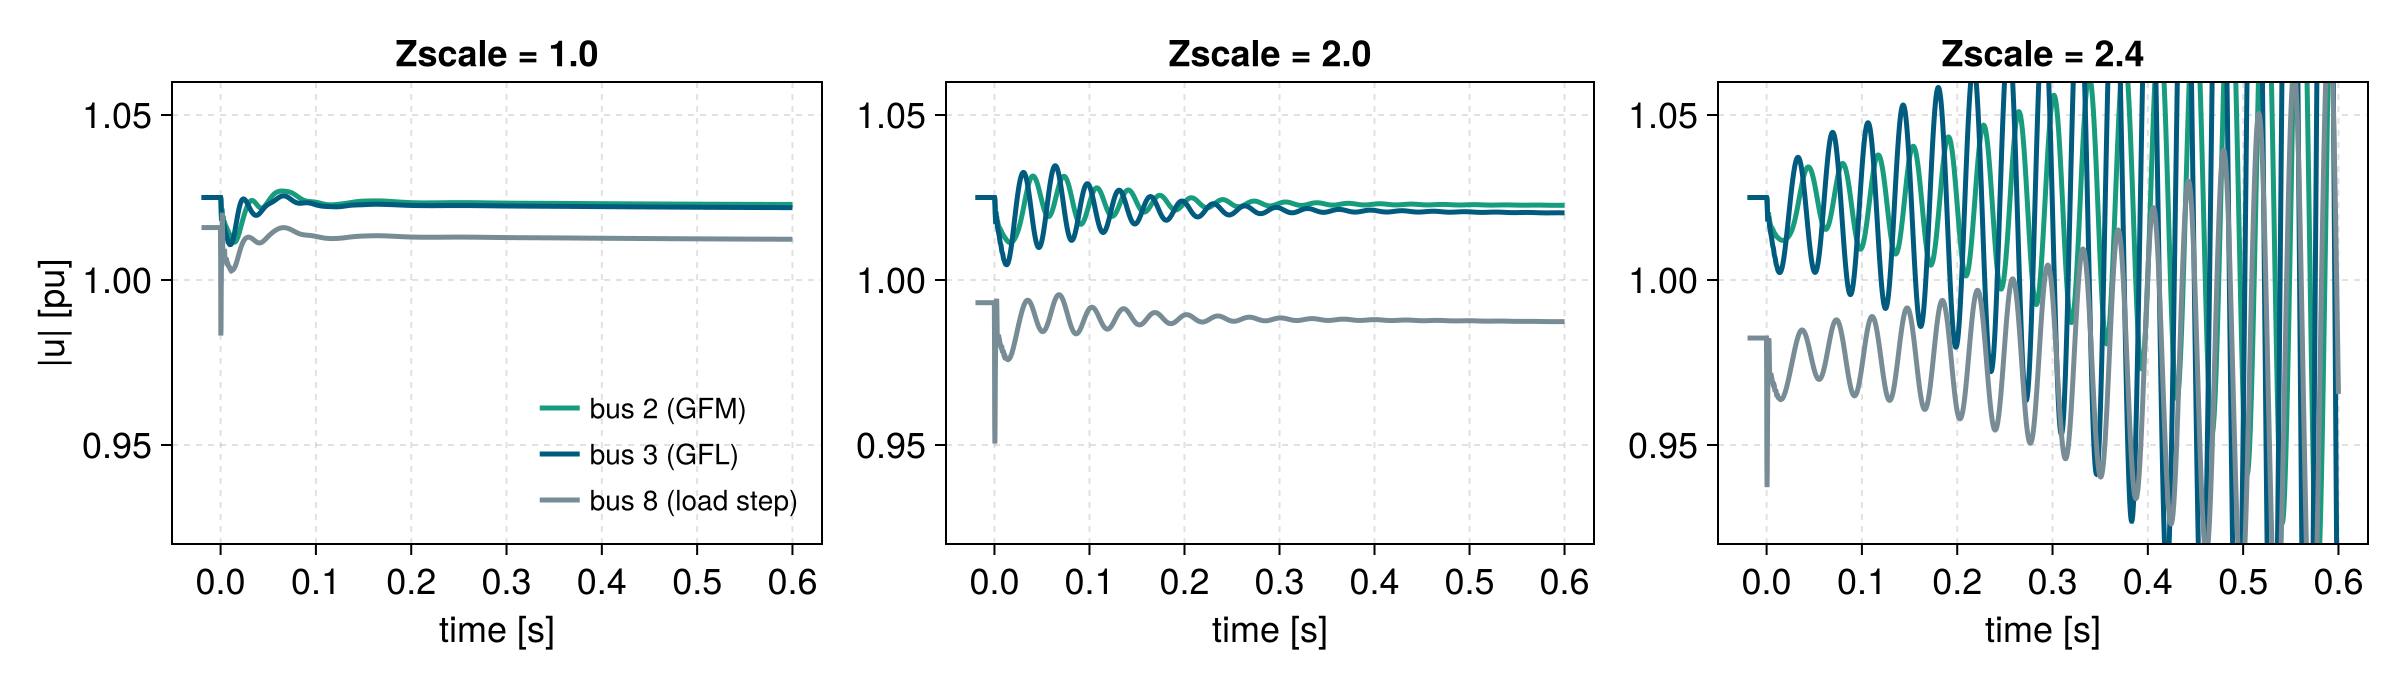

In [5]:
function load_step_problem(s; tspan=(-5.0, 0.6), ΔG=1.1)
    affect! = integrator -> begin
        st = NWState(integrator)
        st[VIndex(8, :load₊G)] *= ΔG
        save_parameters!(integrator)
    end
    ODEProblem(extract_nw(s), s, tspan; add_nw_cb=PresetTimeCallback(0.0, affect!))
end

td_cases = [1.0, 2.0, 2.4]
td_sols = [solve(load_step_problem(op(Z)), Rodas5P()) for Z in td_cases]

let fig = Figure(size=(1200, 340))
    ts = range(-0.02, 0.6; length=3000)
    for (k, (Z, sol)) in enumerate(zip(td_cases, td_sols))
        ax = Axis(fig[1, k]; title="Zscale = $Z", xlabel="time [s]", ylabel=k == 1 ? "|u| [pu]" : "")
        lines!(ax, ts, sol(ts; idxs=VIndex(2, :busbar₊u_mag)).u; color=GREEN, label="bus 2 (GFM)")
        lines!(ax, ts, sol(ts; idxs=VIndex(3, :busbar₊u_mag)).u; color=BLUE, label="bus 3 (GFL)")
        lines!(ax, ts, sol(ts; idxs=VIndex(8, :busbar₊u_mag)).u; color=GREY, label="bus 8 (load step)")
        ylims!(ax, 0.92, 1.06)
        k == 1 && axislegend(ax; position=:rb, framevisible=false, labelsize=14)
    end
    exportfig("td_load_step", fig)
end

## 2 Modal analysis and participation factors

`linearize_network` differentiates the network right-hand side with ForwardDiff (exact Jacobian, no step size);
`reduce_dae` eliminates algebraic variables (Schur complement). Eigenvalues come from LAPACK, participation factors
from the left and right eigenvectors.

In [6]:
Aₛ(s) = reduce_dae(linearize_network(s)).A
inband(λ) = 5 < imag(hz(λ)) < 150                  # converter-driven modes 5–150 Hz (upper half plane)
λ_nom = eigvals(Aₛ(op(1.0)))
λ_c0 = argmin(λ -> inband(λ) ? ζ(λ) : Inf, λ_nom)  # least-damped converter mode at nominal strength
@printf("least-damped converter mode at Zscale = 1: %.2f %+.2fj Hz, ζ = %.3f\n", reim(hz(λ_c0))..., ζ(λ_c0))

least-damped converter mode at Zscale = 1: -5.49 +43.59j Hz, ζ = 0.125


Near the stability limit (`Zscale` = 2.25) the critical mode is the converter mode with the largest real part.

In [7]:
const Z_NEAR = 2.25
λ_near = eigvals(Aₛ(op(Z_NEAR)))
λ_c1 = argmax(λ -> inband(λ) ? real(λ) : -Inf, λ_near)
@printf("critical mode at Zscale = %.2f: %.2f %+.2fj Hz, ζ = %.4f\n", Z_NEAR, reim(hz(λ_c1))..., ζ(λ_c1))

critical mode at Zscale = 2.25: -0.08 +27.64j Hz, ζ = 0.0029


Participation factors per state carry the symbolic state names; summing them per component gives the
participation of each **device** (aggregated participation factors).

Participation Factors:
  Mode  Real (Hz)  Imag (Hz)  Factor   State
  ─────────────────────────────────────────────────────────────────
  70    -0.0808     27.64     0.1552   VIndex(3, :gfl₊csrc₊cc1₊γ_d)
                              0.1443   VIndex(3, :gfl₊csrc₊cc1₊γ_q)
                              0.1277   VIndex(3, :gfl₊csrc₊pll₊θ)
                              0.08483  VIndex(2, :gfm₊vsrc₊cc1₊γ_q)
                              0.05858  VIndex(2, :gfm₊vsrc₊vc₊γ_q)
                              0.05536  VIndex(2, :gfm₊vsrc₊cc1₊γ_d)
                              0.05145  VIndex(3, :gfl₊csrc₊vc₊γ_q)
                              0.04973  VIndex(3, :gfl₊csrc₊vc₊γ_d)


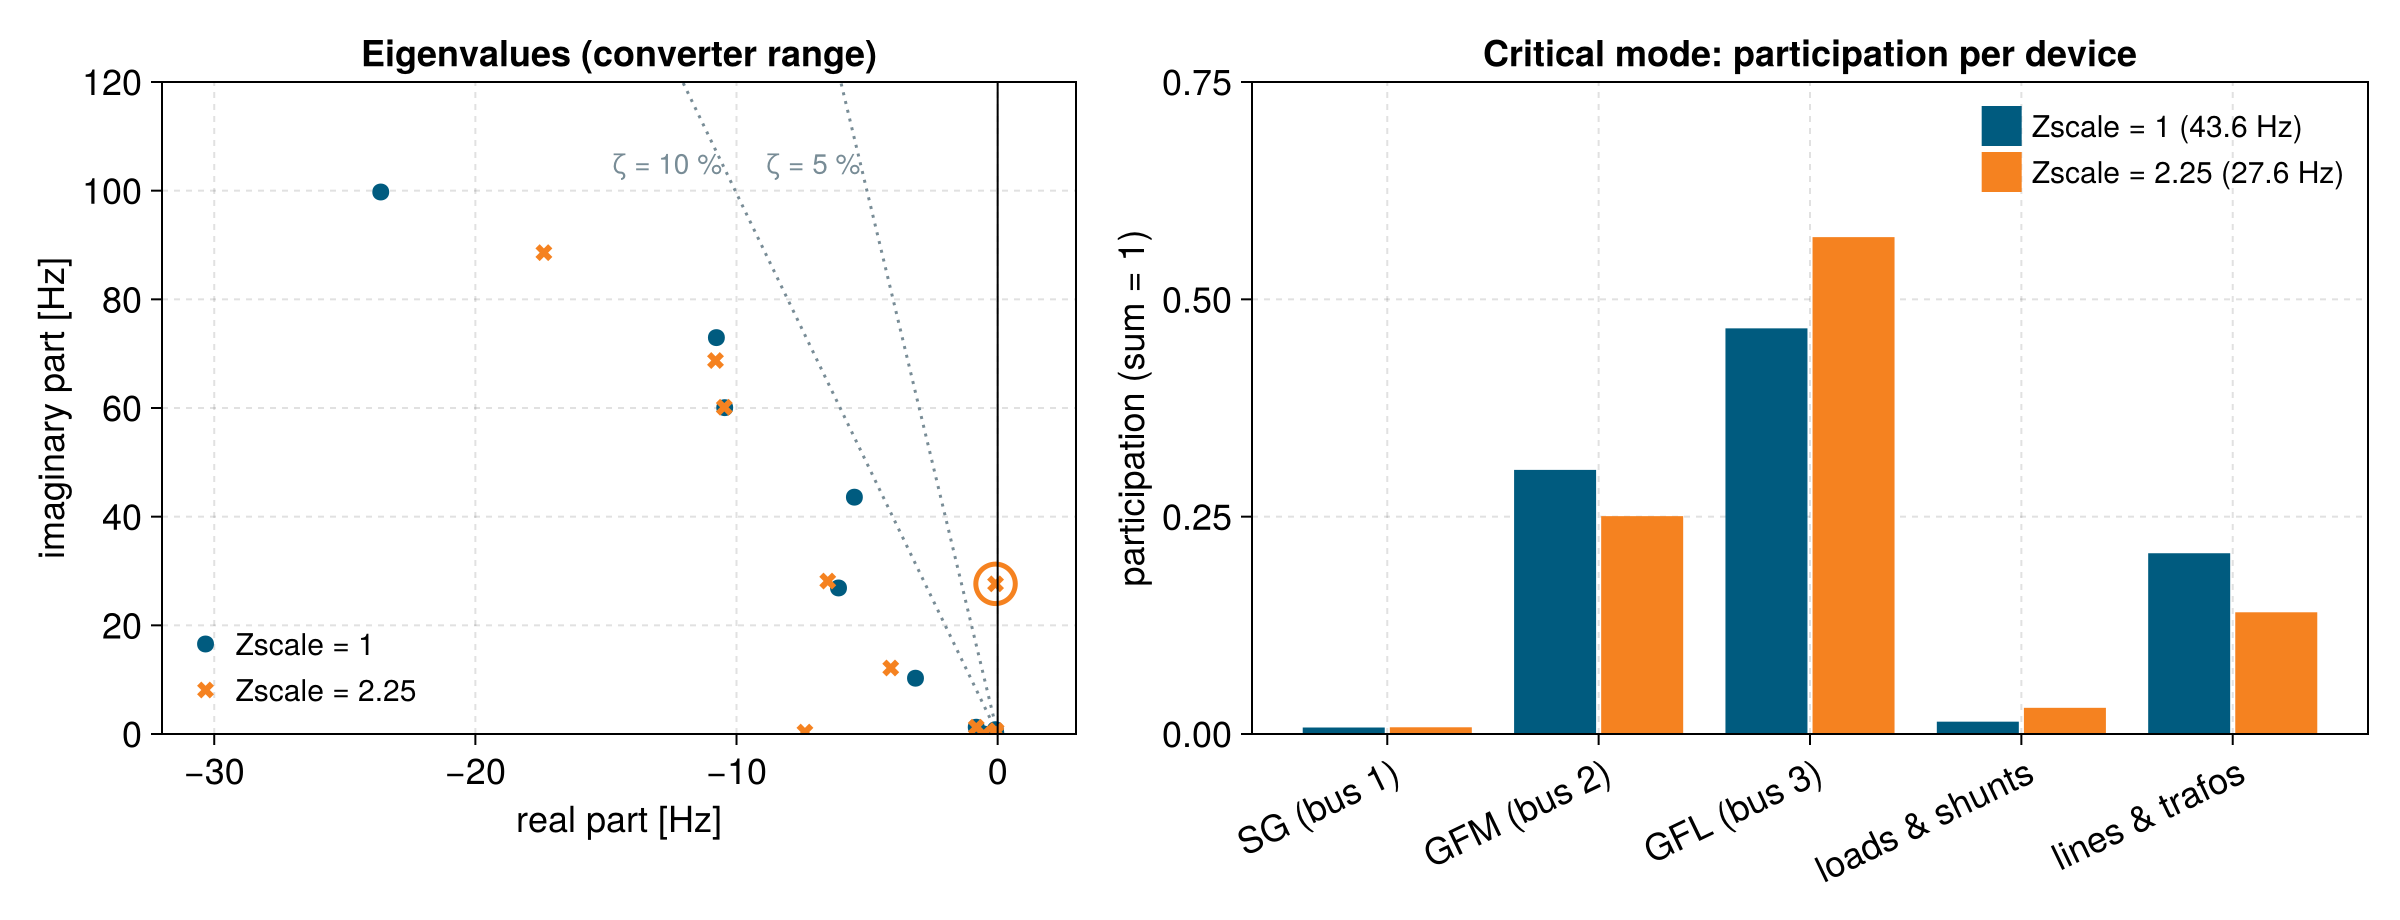

In [8]:
show_participation_factors(op(Z_NEAR); modes=λ -> abs(λ - λ_c1) < 1e-6, threshold=0.04)

const GROUPS = ["SG (bus 1)", "GFM (bus 2)", "GFL (bus 3)", "loads & shunts", "lines & trafos"]
function participation_by_device(s, λt)
    pf = participation_factors(s)
    i = argmin(abs.(pf.eigenvalues .- λt))
    agg = zeros(length(GROUPS))
    for (k, sym) in enumerate(pf.sym)
        g = sym isa VIndex ? min(sym.compidx, 4) : 5
        agg[g] += pf.pfactors[k, i]
    end
    agg
end
pf_nom = participation_by_device(op(1.0), λ_c0)
pf_near = participation_by_device(op(Z_NEAR), λ_c1)

let fig = Figure(size=(1200, 460))
    ax1 = Axis(fig[1, 1]; xlabel="real part [Hz]", ylabel="imaginary part [Hz]", title="Eigenvalues (converter range)")
    for z in (0.05, 0.10)                                   # constant damping-ratio lines
        lines!(ax1, [0, -z / sqrt(1 - z^2) * 120], [0, 120]; color=GREY, linestyle=:dot, linewidth=1.5)
        text!(ax1, -z / sqrt(1 - z^2) * 105, 105; text="ζ = $(round(Int, 100z)) %", color=GREY, fontsize=14, align=(:right, :center))
    end
    for (λs, c, m, lab) in ((λ_nom, BLUE, :circle, "Zscale = 1"), (λ_near, ORANGE, :xcross, "Zscale = $Z_NEAR"))
        sel = filter(λ -> -32 < real(hz(λ)) < 3 && 0 < imag(hz(λ)) < 120, λs)
        scatter!(ax1, real.(hz.(sel)), imag.(hz.(sel)); color=c, marker=m, markersize=12, label=lab)
    end
    scatter!(ax1, [real(hz(λ_c1))], [imag(hz(λ_c1))]; color=:transparent, strokecolor=ORANGE, strokewidth=2.5, markersize=28)
    vlines!(ax1, 0; color=:black, linewidth=1)
    xlims!(ax1, -32, 3); ylims!(ax1, 0, 120)
    axislegend(ax1; position=:lb, framevisible=false, labelsize=15)

    ax2 = Axis(fig[1, 2]; xticks=(1:5, GROUPS), xticklabelrotation=π/7, ylabel="participation (sum = 1)",
        title="Critical mode: participation per device")
    barplot!(ax2, vcat(1:5, 1:5), vcat(pf_nom, pf_near); dodge=vcat(fill(1, 5), fill(2, 5)),
        color=vcat(fill(BLUE, 5), fill(ORANGE, 5)))
    elements = [PolyElement(color=BLUE), PolyElement(color=ORANGE)]
    axislegend(ax2, elements, [@sprintf("Zscale = 1 (%.1f Hz)", imag(hz(λ_c0))), @sprintf("Zscale = %.2f (%.1f Hz)", Z_NEAR, imag(hz(λ_c1)))];
        position=:rt, framevisible=false, labelsize=15)
    ylims!(ax2, 0, 0.75)
    colsize!(fig.layout, 1, Relative(0.45))
    exportfig("modal_participation", fig)
end

## 3 Eigenvalue sensitivities

$\partial\lambda/\partial p = \mathbf w^\top (\partial \mathbf A_s/\partial p)\, \mathbf v$ with $\partial\mathbf A_s/\partial p$ from
**nested forward-mode AD** (a dual number for $p$ inside the dual numbers of the Jacobian): exact and cheap for all
controller parameters at once. The scaled sensitivity $p\,\partial\lambda/\partial p$ is the eigenvalue shift for a
100 % parameter change. Sensitivities are evaluated at a frozen operating point; this is exact for gains that do not
change the equilibrium (proportional gains, PLL gains).

In [9]:
ctrl = filter(SII.parameter_symbols(nw)) do p
    p isa VIndex && p.compidx in (2, 3) && occursin(r"(KP|KI|Kp|Ki|_F$|τ_p|τ_q|Kq|X_virt|R_virt)", string(p.subidx))
end
idx_of(s, λt) = argmin(abs.(eigvals(Aₛ(s)) .- λt))   # mode index in `eigen` ordering
sens_nom = eigenvalue_sensitivity(op(1.0), idx_of(op(1.0), λ_c0); params=ctrl)
sens_near = eigenvalue_sensitivity(op(Z_NEAR), idx_of(op(Z_NEAR), λ_c1); params=ctrl)
println(length(ctrl), " controller parameters of the GFM (bus 2) and the GFL (bus 3)")
show_eigenvalue_sensitivity(sens_near; sortby=:realmag, threshold=0.5)

┌ Warning: The supplied DiffCache was too small and was enlarged. This incurs allocations
│         on the first call to `get_tmp`. If few calls to `get_tmp` occur and optimal performance is essential,
│         consider changing 'N'/chunk size of this DiffCache to 23.
└ @ PreallocationTools ~/.julia\packages\PreallocationTools\dNQ2d\src\PreallocationTools.jl:566
23 controller parameters of the GFM (bus 2) and the GFL (bus 3)
Eigenvalue Sensitivity for mode 70: λ = -0.0808 ± 27.64j Hz
  Parameter                    Value   Real (Hz)  Imag (Hz)  |p·∂λ/∂p| (Hz)  ∠ (deg)
  ──────────────────────────────────────────────────────────────────────────────────
  VIndex(3, :gfl₊csrc₊CC2_F)    1       17.47     -6.219     18.54           -19.59
  VIndex(3, :gfl₊csrc₊VC_KI)    317.4   6.543      6.471     9.202            44.68
  VIndex(3, :gfl₊csrc₊CC1_KI)   63      4.811      34.37     34.71            82.03
  VIndex(3, :gfl₊csrc₊CC1_KP)   0.063  -4.018     -1.364     4.243           -161.3
  VI

Check: change the GFL current-controller gain `CC1_KP` by +5 % (it does not move the operating point) and compare the
predicted with the recomputed eigenvalue.

+5% CC1_KP: predicted -0.2817 +27.5675j Hz, recomputed -0.2826 +27.5634j Hz


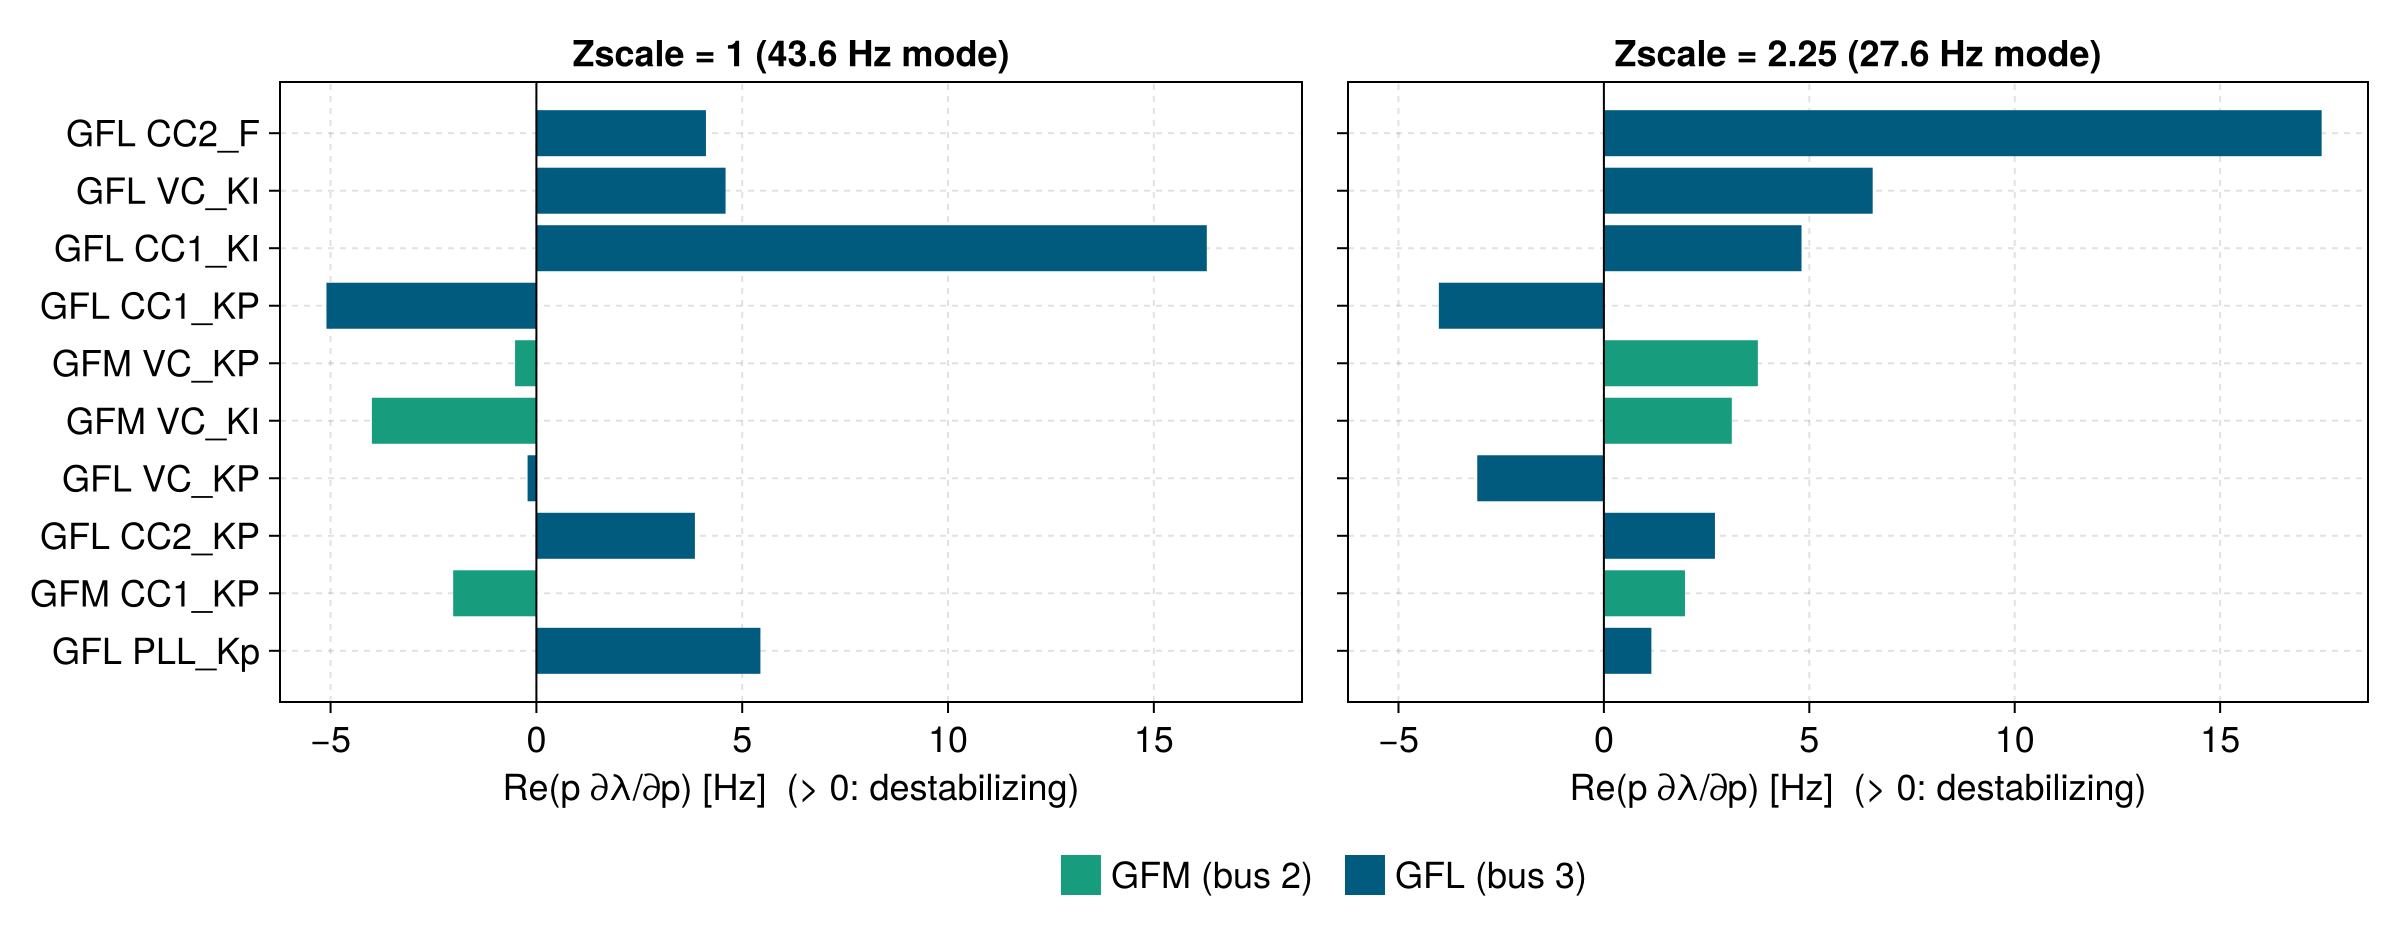

In [10]:
function As_with(s, pidx, factors)                    # Aₛ with scaled parameters at the operating point of s
    p = copy(pflat(s)); p[pidx] .*= factors
    nws = extract_nw(s)
    J = ForwardDiff.jacobian(x -> (du = zeros(eltype(x), length(x)); nws(du, x, p, s.t); du), uflat(s))
    reduce_dae(NetworkDescriptorSystem(; M=nws.mass_matrix, A=J)).A
end
let k = findfirst(==(VIndex(3, :gfl₊csrc₊CC1_KP)), sens_near.param_syms)
    pidx = SII.parameter_index(nw, sens_near.param_syms[k])
    λpred = sens_near.eigenvalue + 0.05 * sens_near.scaled_sensitivities[k]
    λs = eigvals(As_with(op(Z_NEAR), [pidx], [1.05]))
    λnew = λs[argmin(abs.(λs .- λpred))]
    @printf("+5%% CC1_KP: predicted %.4f %+.4fj Hz, recomputed %.4f %+.4fj Hz\n", reim(hz(λpred))..., reim(hz(λnew))...)
end

let fig = Figure(size=(1200, 470))
    label(sym) = (sym.compidx == 2 ? "GFM " : "GFL ") * replace(string(sym.subidx), r"^(gfm|gfl)₊(vsrc|csrc|droop)₊" => "")
    order = sortperm(abs.(real.(sens_near.scaled_sensitivities)); rev=true)[1:10]
    axs = Axis[]
    for (col, (res, title)) in enumerate(((sens_nom, @sprintf("Zscale = 1 (%.1f Hz mode)", imag(hz(λ_c0)))),
                                          (sens_near, @sprintf("Zscale = %.2f (%.1f Hz mode)", Z_NEAR, imag(hz(λ_c1))))))
        vals = [real(res.scaled_sensitivities[j]) / 2π for j in order]
        ax = Axis(fig[1, col]; yticks=(1:10, label.(res.param_syms[order])), yreversed=true, title,
            xlabel="Re(p ∂λ/∂p) [Hz]  (> 0: destabilizing)", yticklabelsvisible=col == 1)
        barplot!(ax, 1:10, vals; direction=:x, color=[res.param_syms[j].compidx == 2 ? GREEN : BLUE for j in order])
        vlines!(ax, 0; color=:black, linewidth=1)
        push!(axs, ax)
    end
    linkxaxes!(axs...)
    Legend(fig[2, :], [PolyElement(color=GREEN), PolyElement(color=BLUE)], ["GFM (bus 2)", "GFL (bus 3)"];
        orientation=:horizontal, framevisible=false)
    exportfig("sensitivities", fig)
end

## 4 Eigenvalue tracking by continuation

Instead of matching eigenvalues between independent sweeps (nearest neighbour), we **continue the eigenpair**
$(\mathbf v, \lambda)$ as a solution of
$$F(\mathbf z, Z) = \begin{bmatrix}(\mathbf A_s(Z) - \lambda \mathbf I)\,\mathbf v\\ \mathbf c^{\mathsf H}\mathbf v - 1\end{bmatrix} = 0,
\qquad \mathbf z = [\mathrm{Re}\,\mathbf v;\ \mathrm{Im}\,\mathbf v;\ \mathrm{Re}\,\lambda;\ \mathrm{Im}\,\lambda]$$
with BifurcationKit.jl. The Jacobian $\partial F/\partial\mathbf z$ comes from ForwardDiff; an event on
$\mathrm{Re}\,\lambda = 0$ locates the Hopf crossing by bisection. The start eigenpair is computed by shift-invert
Krylov iteration (KrylovKit.jl), which only needs the eigenvalues near a target.

In [11]:
const NX = size(Aₛ(s0), 1)
pack(v, λ) = vcat(real(v), imag(v), real(λ), imag(λ))
unpack(z) = (complex.(z[1:NX], z[NX+1:2NX]), complex(z[2NX+1], z[2NX+2]))
function eigres(z, A, c)
    v, λ = unpack(z)
    r = A * v - λ * v
    n = dot(c, v) - 1
    vcat(real(r), imag(r), real(n), imag(n))
end
"eigenpairs closest to σ by shift-invert Krylov iteration (μ = 1/(λ − σ))"
function shift_invert(A, σ; nev=3)
    F = lu(sparse(A - σ * I))
    μ, V, _ = eigsolve(x -> F \ x, rand(Xoshiro(1), ComplexF64, size(A, 1)), nev, :LM)  # fixed seed: reproducible branch
    (; λ = σ .+ 1 ./ μ[1:nev], V = V[1:nev])
end
"condition number ‖w‖‖v‖/|wᵀv| of the eigenvalue of A closest to λ and the distance to the next eigenvalue"
function eig_condition(A, λ)
    E = eigen(A); W = inv(E.vectors); i = argmin(abs.(E.values .- λ))
    v, w = E.vectors[:, i], W[i, :]
    (; err = abs(E.values[i] - λ), cond = norm(v) * norm(w) / abs(transpose(w) * v),
       gap = minimum(abs(E.values[j] - E.values[i]) for j in eachindex(E.values) if j != i))
end

si = shift_invert(Aₛ(op(1.0)), λ_c0)
cZ = si.V[1] / dot(si.V[1], si.V[1])
probZ = BifurcationProblem((z, p) -> eigres(z, Aₛ(op(p.Z)), cZ), pack(si.V[1], si.λ[1]), (Z = 1.0,), (@optic _.Z);
    J = (z, p) -> (A = Aₛ(op(p.Z)); ForwardDiff.jacobian(zz -> eigres(zz, A, cZ), z)),
    record_from_solution = (x, p; k...) -> merge((λr = real(hz(unpack(x)[2])), λi = imag(hz(unpack(x)[2]))),
                                                 eig_condition(Aₛ(op(p)), unpack(x)[2])))
hopf_event = ContinuousEvent(1, (it, state) -> getx(state)[2NX+1], ("Hopf",))

BifurcationKit.ContinuousEvent{ComposedFunction{typeof(BifurcationKit.convert_to_tuple_eve), Main.var"##277".var"#51#52"}, Tuple{String}, Int64, typeof(BifurcationKit.default_finalise_event!), Nothing}(1, BifurcationKit.convert_to_tuple_eve ∘ Main.var"##277".var"#51#52"(), false, ("Hopf",), 0, BifurcationKit.default_finalise_event!, nothing)

Residual tolerance 1e-7: ‖Aₛ‖ ≈ 9e8 for this stiff quasi-EMT model, i.e. ≈ 1e-16 relative.

In [12]:
optsZ = ContinuationPar(p_min=0.25, p_max=3.0, ds=0.02, dsmax=0.025, dsmin=1e-5, max_steps=600,
    newton_options=NewtonPar(tol=1e-7, max_iterations=10), detect_bifurcation=0, detect_fold=false,
    detect_event=2, tol_param_bisection_event=1e-8, max_bisection_steps=40)
t_track = @elapsed brZ = continuation(probZ, Natural(), optsZ; event=hopf_event, bothside=true, verbosity=0)
trZ = let b = brZ.branch, i = filter(k -> 0.25 <= b.param[k] <= 3.0, sortperm(b.param))
    (; Z = b.param[i], λ = complex.(b.λr[i], b.λi[i]), err = b.err[i], cond = b.cond[i], gap = b.gap[i])
end
Zstar = first(sp.param for sp in brZ.specialpoint if sp.type == :Hopf)
@printf("continuation: %d points in %.1f s, Hopf crossing at Zscale* = %.4f; max distance to dense eigenvalues %.1e rad/s\n",
    length(trZ.Z), t_track, Zstar, maximum(trZ.err))
iclose = argmin(trZ.gap)
@printf("closest approach to another eigenvalue: %.2f Hz at Zscale = %.3f (eigenvalue condition number %.2g)\n",
    trZ.gap[iclose] / 2π, trZ.Z[iclose], trZ.cond[iclose])

continuation: 112 points in 18.5 s, Hopf crossing at Zscale* = 2.2636; max distance to dense eigenvalues 2.8e-07 rad/s
closest approach to another eigenvalue: 2.31 Hz at Zscale = 0.255 (eigenvalue condition number 6.3e+02)


For comparison: nearest-neighbour matching on an equidistant grid, started on the same mode.

nearest neighbour jumps to another mode at Zscale = 0.375


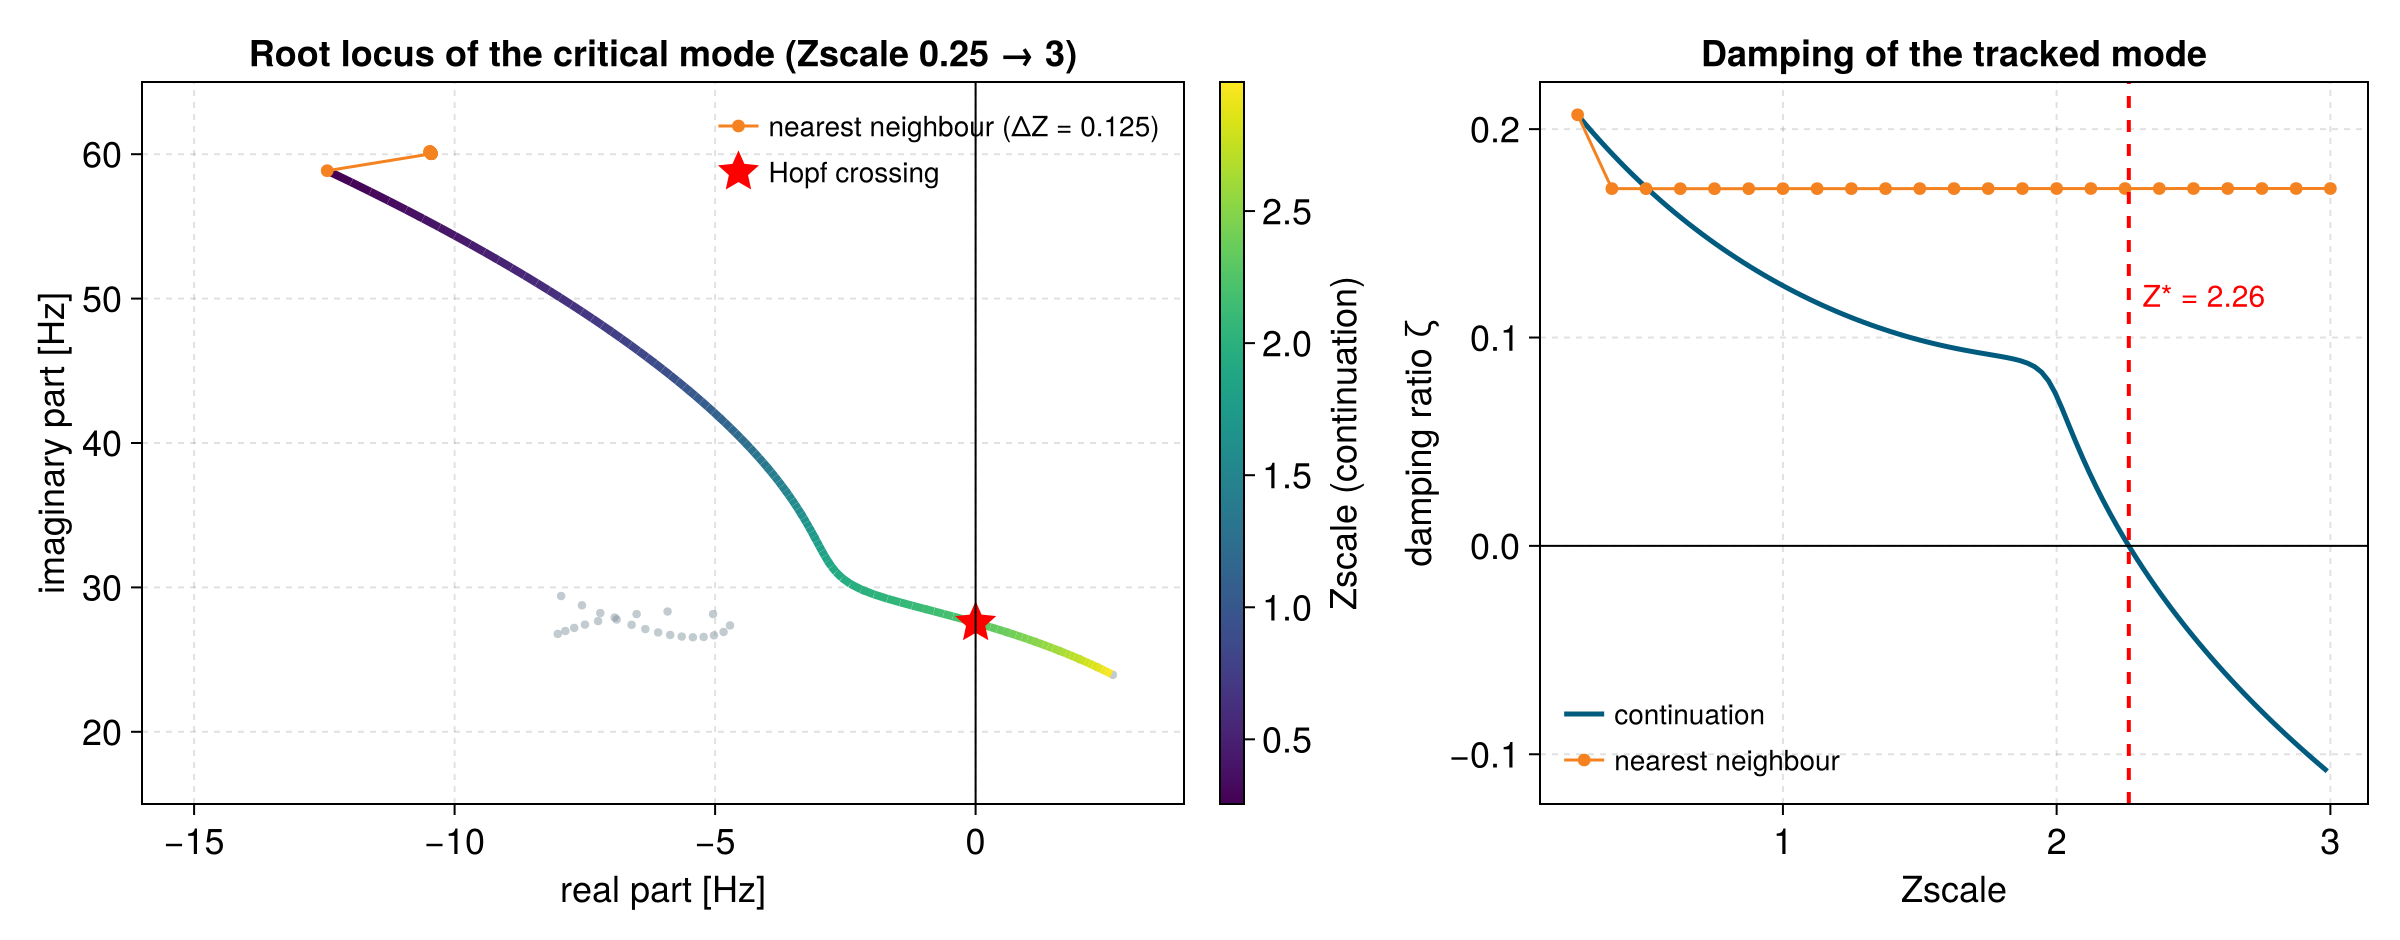

In [13]:
Zgrid = collect(0.25:0.125:3.0)
spectra = [eigvals(Aₛ(op(Z))) for Z in Zgrid]
λcont(Z) = let k = clamp(searchsortedlast(trZ.Z, Z), 1, length(trZ.Z) - 1), w = (Z - trZ.Z[k]) / (trZ.Z[k+1] - trZ.Z[k])
    2π * ((1 - w) * trZ.λ[k] + w * trZ.λ[k+1])
end
nn = let λp = λcont(Zgrid[1])
    map(λs -> (λp = λs[argmin(abs.(λs .- λp))]), spectra)
end
truth = [λs[argmin(abs.(λs .- λcont(Z)))] for (Z, λs) in zip(Zgrid, spectra)]
iswap = findfirst(k -> abs(nn[k] - truth[k]) > 1e-6 * abs(truth[k]), eachindex(Zgrid))
println(isnothing(iswap) ? "nearest neighbour follows the same mode" :
    @sprintf("nearest neighbour jumps to another mode at Zscale = %.3f", Zgrid[iswap]))

let fig = Figure(size=(1200, 470))
    ax1 = Axis(fig[1, 1]; xlabel="real part [Hz]", ylabel="imaginary part [Hz]", title="Root locus of the critical mode (Zscale 0.25 → 3)")
    for λs in spectra
        sel = filter(λ -> -16 < real(hz(λ)) < 4 && 15 < imag(hz(λ)) < 65, λs)
        scatter!(ax1, real.(hz.(sel)), imag.(hz.(sel)); color=(GREY, 0.45), markersize=6)
    end
    lines!(ax1, real.(trZ.λ), imag.(trZ.λ); color=trZ.Z, colormap=:viridis, linewidth=4)
    scatterlines!(ax1, real.(hz.(nn)), imag.(hz.(nn)); color=ORANGE, markersize=9, linewidth=1.5, label="nearest neighbour (ΔZ = 0.125)")
    scatter!(ax1, [real(hz(λcont(Zstar)))], [imag(hz(λcont(Zstar)))]; color=:red, marker=:star5, markersize=24, label="Hopf crossing")
    vlines!(ax1, 0; color=:black, linewidth=1)
    xlims!(ax1, -16, 4); ylims!(ax1, 15, 65)
    axislegend(ax1; position=:rt, framevisible=false, labelsize=14)
    Colorbar(fig[1, 2]; limits=extrema(trZ.Z), colormap=:viridis, label="Zscale (continuation)")

    ax2 = Axis(fig[1, 3]; xlabel="Zscale", ylabel="damping ratio ζ", title="Damping of the tracked mode")
    lines!(ax2, trZ.Z, ζ.(trZ.λ); color=BLUE, label="continuation")
    scatterlines!(ax2, Zgrid, ζ.(nn); color=ORANGE, markersize=9, linewidth=1.5, label="nearest neighbour")
    hlines!(ax2, 0; color=:black, linewidth=1)
    vlines!(ax2, Zstar; color=:red, linestyle=:dash, linewidth=2)
    text!(ax2, Zstar + 0.05, 0.12; text=@sprintf("Z* = %.2f", Zstar), color=:red, fontsize=15, align=(:left, :center))
    axislegend(ax2; position=:lb, framevisible=false, labelsize=14)
    colsize!(fig.layout, 1, Relative(0.55))
    exportfig("eigen_tracking", fig)
end

## 5 Stability boundary: grid strength vs. PLL bandwidth

Scaling the PLL gains as $K_p\,\kappa$, $K_i\,\kappa^2$ scales the PLL bandwidth by $\kappa$ without moving the
operating point (phase error and frequency deviation are zero in steady state), so $\mathbf A_s(\kappa)$ needs no
re-initialization: it is the AD Jacobian at the same state with modified gains. The boundary
$Z^*(\kappa)$ is traced by **pseudo-arclength continuation (PALC)** of the augmented system
$[F(\mathbf z, Z; \kappa);\ \mathrm{Re}\,\lambda] = 0$ with unknowns $(\mathbf z, Z)$ and continuation parameter $\kappa$.
The condition $\mathrm{Re}\,\lambda = 0$ turns $Z$ into an unknown. Derivatives: the eigenpair block by ForwardDiff;
the column $\partial/\partial Z$ involves a new power flow and initialization and is approximated by a central
difference ($h = 10^{-3}$, well above the initialization tolerance); $\partial/\partial\kappa$ is computed by
BifurcationKit's PALC corrector with a forward difference (cheap and accurate, because $\kappa$ does not move the
operating point). Approximate Jacobians only slow Newton down; the converged points satisfy the equations to the
Newton tolerance.

PALC steps along the arclength of the curve in $(\mathbf z, Z, \kappa)$, so it also passes turning points.
Parametrized by $Z$, the boundary has one: below the "nose" no bandwidth is critical, above it two are.

In [14]:
const PLLIDX = SII.parameter_index(nw, [VIndex(3, :gfl₊csrc₊PLL_Kp), VIndex(3, :gfl₊csrc₊PLL_Ki)])
"Aₛ at the operating point of `s` with PLL bandwidth scaled by κ (κ may be a dual number → nested AD)"
function As_pll(s, κ)
    p = Vector{typeof(κ)}(pflat(s)); p[PLLIDX[1]] *= κ; p[PLLIDX[2]] *= κ^2
    nws = extract_nw(s)
    J = ForwardDiff.jacobian(x -> (du = zeros(promote_type(eltype(x), typeof(κ)), length(x)); nws(du, x, p, s.t); du), uflat(s))
    reduce_dae(NetworkDescriptorSystem(; M=nws.mass_matrix, A=J)).A
end
zH = let x = first(sp.x for sp in brZ.specialpoint if sp.type == :Hopf); x end
cH = let (v, _) = unpack(zH); v / dot(v, v) end
Gb(y, κ) = vcat(eigres(y[1:end-1], As_pll(op(y[end]), κ), cH), y[2NX+1])
function Jb(y, κ)
    Z = y[end]; A = As_pll(op(Z), κ)
    Jz = ForwardDiff.jacobian(z -> vcat(eigres(z, A, cH), z[2NX+1]), y[1:end-1])
    h = 1e-3
    dZ = (Gb(vcat(y[1:end-1], Z + h), κ) - Gb(vcat(y[1:end-1], Z - h), κ)) / 2h
    hcat(Jz, dZ)
end
probb = BifurcationProblem((y, p) -> Gb(y, p.κ), vcat(zH, Zstar), (κ = 1.0,), (@optic _.κ);
    J = (y, p) -> Jb(y, p.κ), record_from_solution = (x, p; k...) -> (Z = x[end], f = x[2NX+2] / 2π))
optsb = ContinuationPar(p_min=0.3, p_max=6.0, ds=0.05, dsmax=0.25, dsmin=1e-5, max_steps=300,
    newton_options=NewtonPar(tol=1e-7, max_iterations=15), detect_bifurcation=0, detect_fold=true)
t_boundary = @elapsed brb = continuation(probb, PALC(), optsb; bothside=true, verbosity=0)
bnd = let b = brb.branch, i = sortperm(b.param)
    (; κ = b.param[i], Z = b.Z[i], f = b.f[i])
end
@printf("boundary: %d points in %.1f s; most critical PLL bandwidth κ = %.2f (Zscale* = %.3f)\n",
    length(bnd.κ), t_boundary, bnd.κ[argmin(bnd.Z)], minimum(bnd.Z))

boundary: 61 points in 84.1 s; most critical PLL bandwidth κ = 2.62 (Zscale* = 1.541)


Validation with dense eigenvalues on a grid.

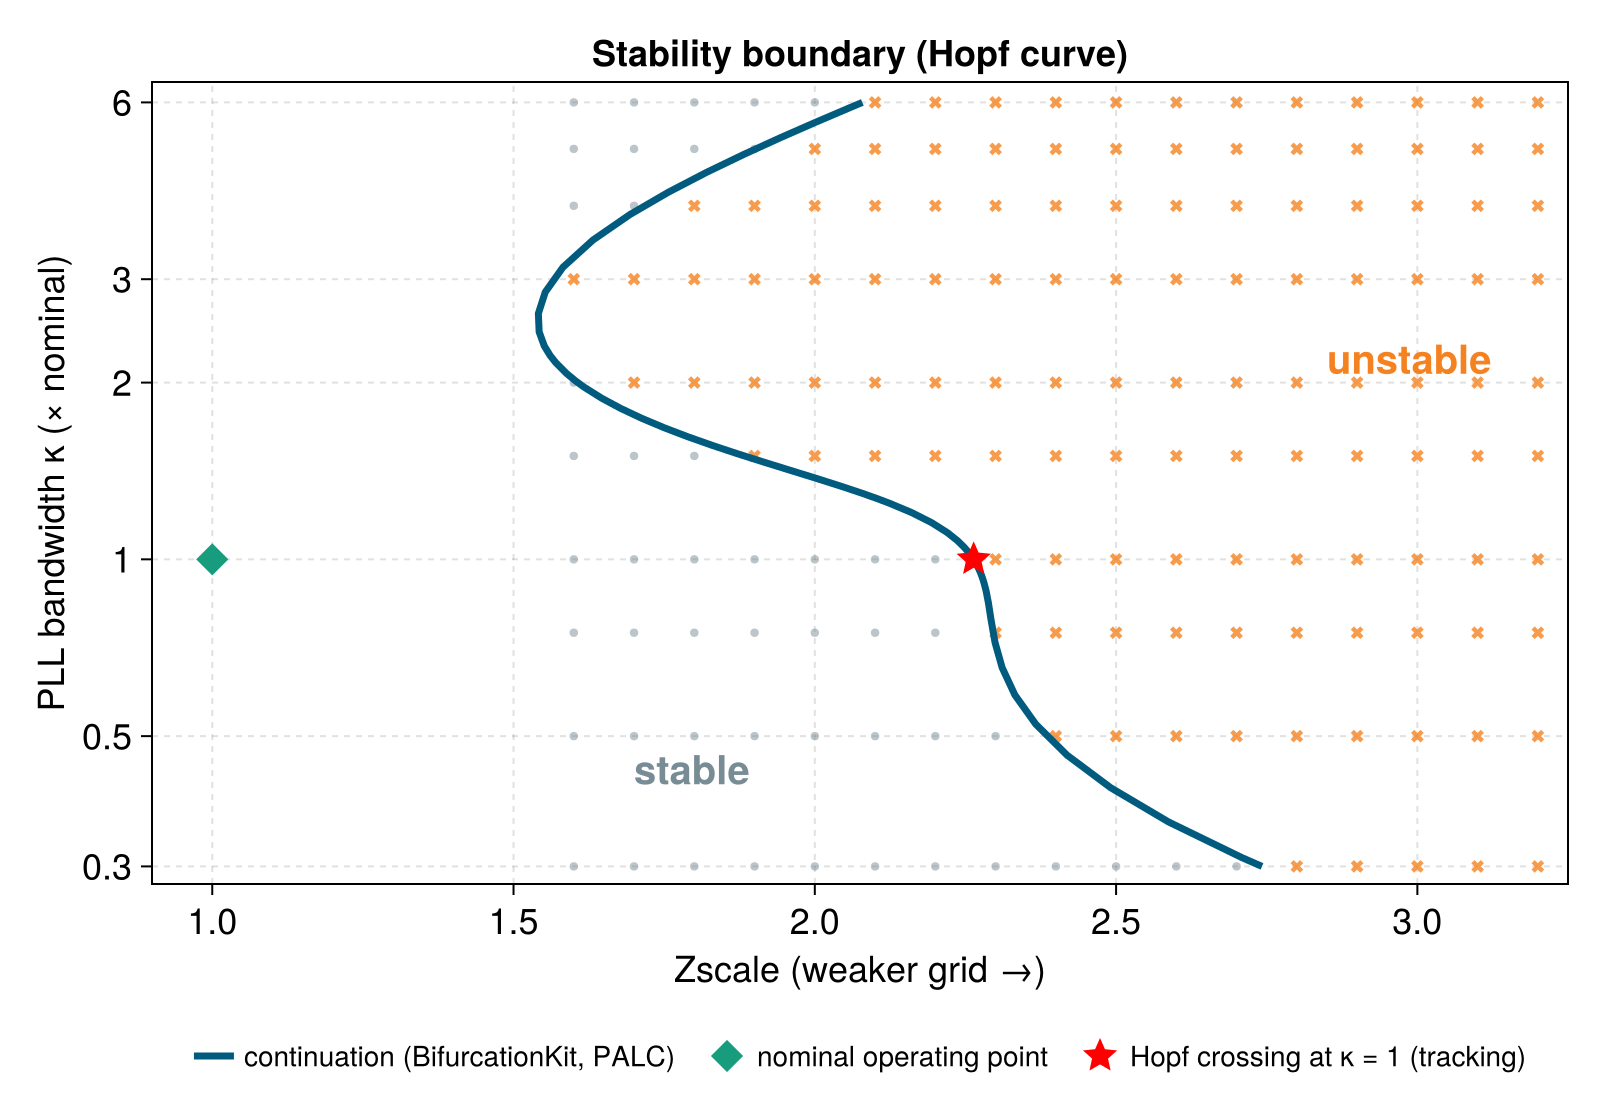

In [15]:
κgrid = [0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0]
Zgrid_b = collect(1.6:0.1:3.2)
unstable = [maximum(real(λ) for λ in eigvals(As_pll(op(Z), κ)) if abs(λ) > 1e-3) > 0 for κ in κgrid, Z in Zgrid_b]

let fig = Figure(size=(800, 560))
    ax = Axis(fig[1, 1]; xlabel="Zscale (weaker grid →)", ylabel="PLL bandwidth κ (× nominal)", yscale=log10,
        yticks=([0.3, 0.5, 1, 2, 3, 6], ["0.3", "0.5", "1", "2", "3", "6"]), title="Stability boundary (Hopf curve)")
    for (i, κ) in enumerate(κgrid), (j, Z) in enumerate(Zgrid_b)
        scatter!(ax, [Z], [κ]; color=unstable[i, j] ? (ORANGE, 0.8) : (GREY, 0.5),
            marker=unstable[i, j] ? :xcross : :circle, markersize=unstable[i, j] ? 9 : 6)
    end
    lines!(ax, bnd.Z, bnd.κ; color=BLUE, linewidth=3.5, label="continuation (BifurcationKit, PALC)")
    scatter!(ax, [1.0], [1.0]; color=GREEN, marker=:diamond, markersize=18, label="nominal operating point")
    scatter!(ax, [Zstar], [1.0]; color=:red, marker=:star5, markersize=20, label="Hopf crossing at κ = 1 (tracking)")
    text!(ax, 2.85, 2.0; text="unstable", color=ORANGE, fontsize=20, font=:bold)
    text!(ax, 1.7, 0.4; text="stable", color=GREY, fontsize=20, font=:bold)
    xlims!(ax, 0.9, 3.25); ylims!(ax, 0.28, 6.5)
    Legend(fig[2, 1], ax; orientation=:horizontal, framevisible=false, labelsize=14)
    exportfig("stability_boundary", fig)
end

## 6 Impedance-based analysis

We cut the network at the GFL bus. **Device:** the bus-3 model (GFL + bus capacitance), an impedance from the
current delivered by the lines to the bus voltage (`linearize_component`). **Grid:** all other components,
assembled from `open_loop_linearization` and closed with the partial `feedback` of ControlSystemsBase.jl. Both are
exact 2×2 (dq) transfer functions from the same AD linearization — no frequency scan.

In [16]:
to_ss(sys) = (r = reduce_dae(sys); ss(Matrix(r.A), Matrix(r.B), Matrix(r.C), Matrix(r.D)))
"cut at bus b → device impedance Zdev (load convention) and grid admittance Ygrid seen from bus b"
function cut_at_bus(s, b)
    (; Zbus, Ynw) = open_loop_linearization(s)
    nv = length(extract_nw(s).im.vertexm)
    Zo = ND.append([linearize_component(s, VIndex(k)) for k in 1:nv if k != b]...)
    isb(sym) = sym.compidx == b
    W1 = findall(isb, Zbus.outsym); U1 = findall(!isb, Zbus.outsym)    # Ynw inputs: bus voltages
    Z1 = findall(isb, Zbus.insym);  Y1 = findall(!isb, Zbus.insym)     # Ynw outputs: bus injections
    Yrest = CS.feedback(to_ss(Ynw), to_ss(Zo); W1, Z1, U1, Y1, pos_feedback=true)
    (; Zdev = to_ss(linearize_component(s, VIndex(b))), Ygrid = -Yrest)
end
let c = cut_at_bus(s0, 3)                                               # consistency check
    λcl = eigvals(CS.feedback(c.Zdev, c.Ygrid).A)
    @assert maximum(minimum(abs.(λ_nom .- λ)) / max(1, abs(λ)) for λ in λcl) < 1e-6
end

Classic impedance-based view: positive-sequence impedances of device and grid. Instability is indicated where the
magnitudes cross with a phase difference close to 180°. (This SISO view neglects the coupling between sequences;
the generalized Nyquist criterion in section 7 is the exact MIMO test.)

Zscale = 1: |Z| crossing at 39.1 Hz, phase margin 14.0°
Zscale = 2.3: |Z| crossing at 21.8 Hz, phase margin 4.0°


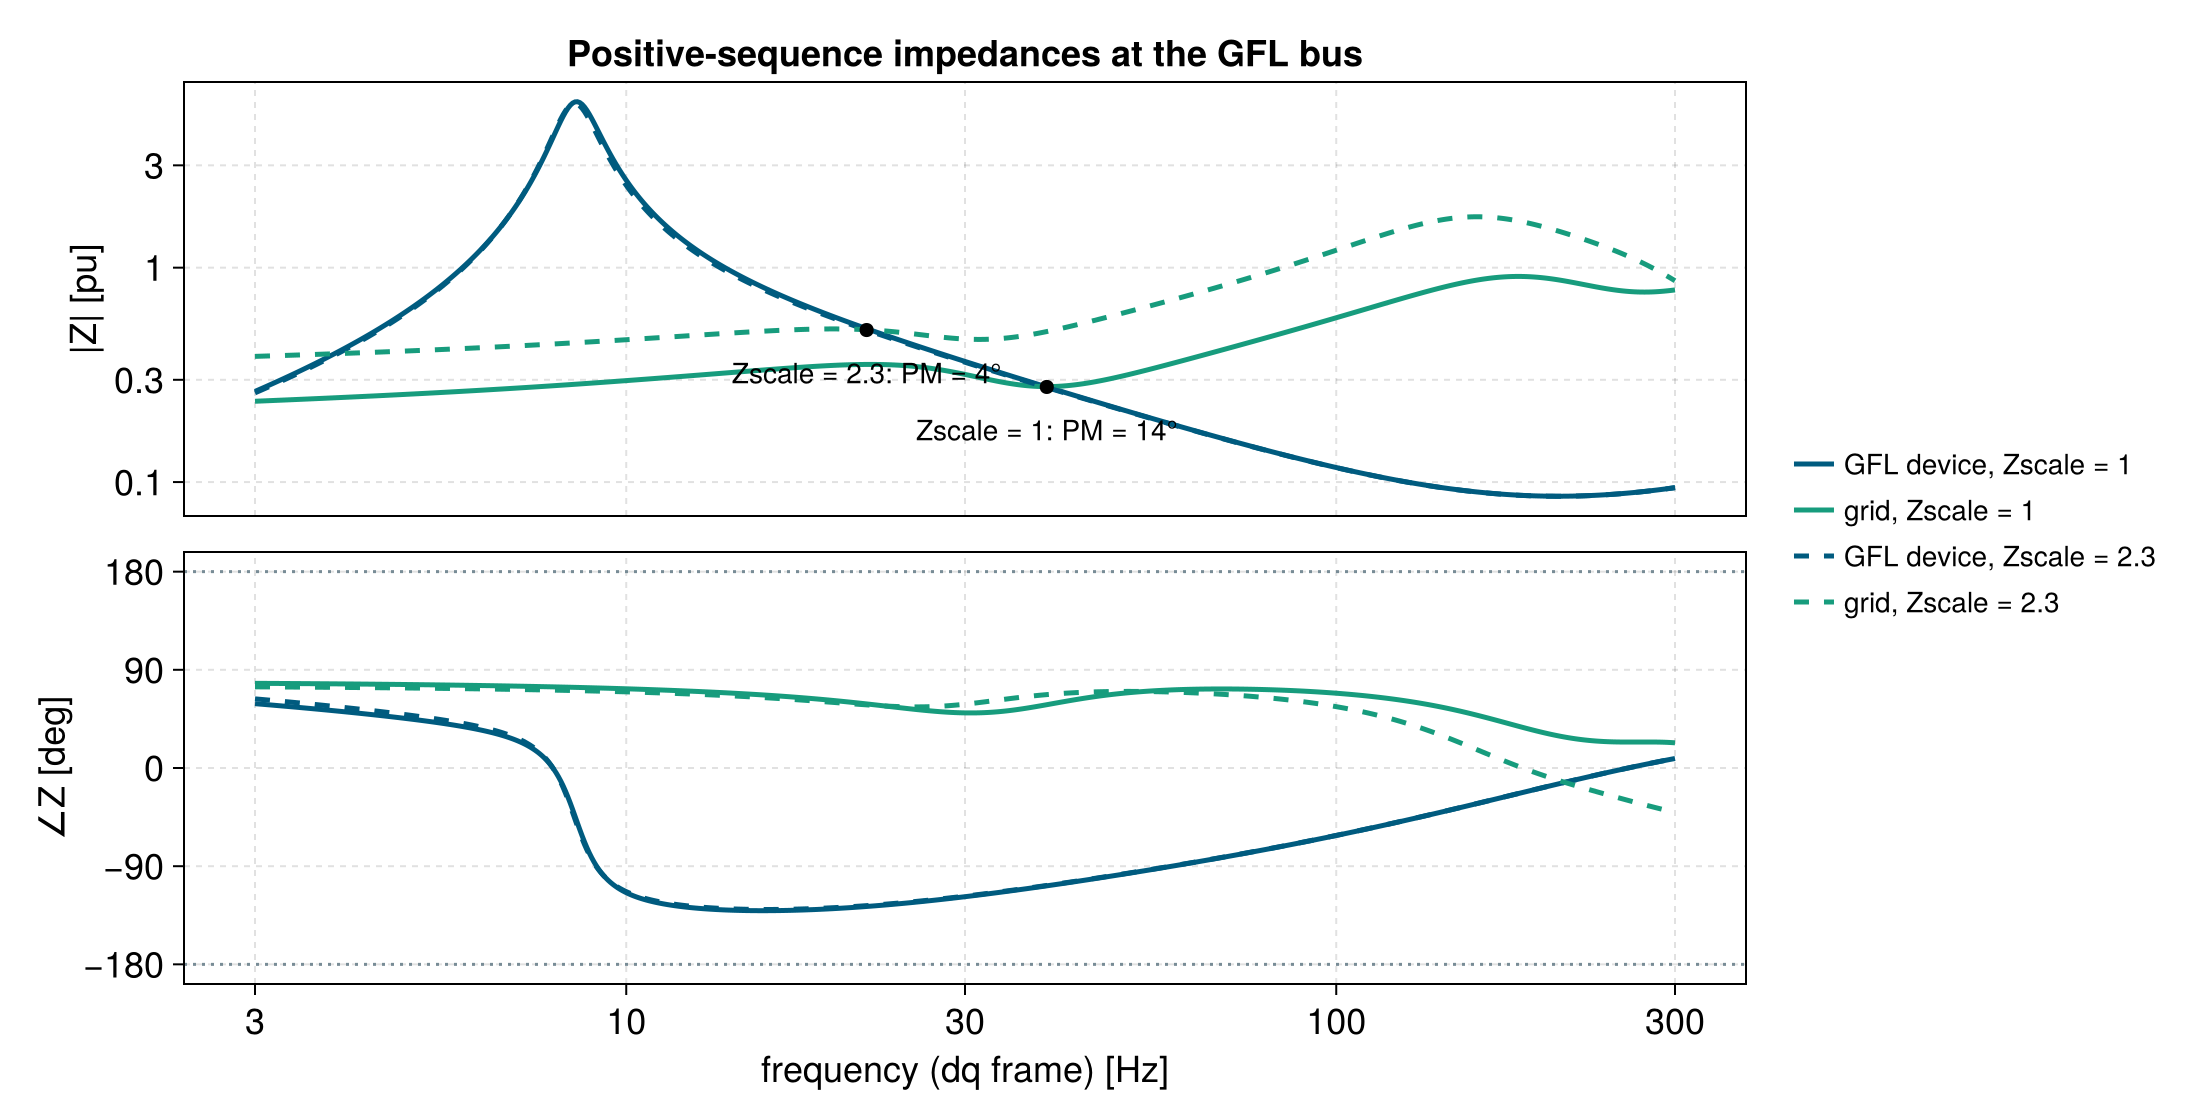

In [17]:
const Tseq = [1.0 1.0im; 1.0 -1.0im]
zpos(M) = (Tseq * M * inv(Tseq))[1, 1]
fs_imp = 10 .^ range(log10(3), log10(300); length=600)
function seq_impedances(s)
    c = cut_at_bus(s, 3)
    Zd = [zpos(freqresp(c.Zdev, [2π * f])[:, :, 1]) for f in fs_imp]
    Zg = [zpos(inv(freqresp(c.Ygrid, [2π * f])[:, :, 1])) for f in fs_imp]
    (; Zd, Zg)
end
imp_cases = [(1.0, "Zscale = 1"), (2.3, "Zscale = 2.3")]
imps = [seq_impedances(op(Z)) for (Z, _) in imp_cases]
crossings = map(zip(imp_cases, imps)) do ((Z, lab), im_)
    k = findfirst(i -> abs(im_.Zd[i]) < abs(im_.Zg[i]) && abs(im_.Zd[i-1]) ≥ abs(im_.Zg[i-1]), 2:length(fs_imp)) + 1
    pm = 180 - abs(rad2deg(angle(im_.Zd[k] / im_.Zg[k])))
    @printf("%s: |Z| crossing at %.1f Hz, phase margin %.1f°\n", lab, fs_imp[k], pm)
    (; k, pm)
end

let fig = Figure(size=(1100, 560))
    fticks = ([3, 10, 30, 100, 300], ["3", "10", "30", "100", "300"])
    axm = Axis(fig[1, 1]; xscale=log10, ylabel="|Z| [pu]", yscale=log10, title="Positive-sequence impedances at the GFL bus",
        xticks=fticks, yticks=([0.1, 0.3, 1, 3], ["0.1", "0.3", "1", "3"]))
    axp = Axis(fig[2, 1]; xscale=log10, ylabel="∠Z [deg]", xlabel="frequency (dq frame) [Hz]", xticks=fticks,
        yticks=[-180, -90, 0, 90, 180])
    for ((Z, lab), im_, ls) in zip(imp_cases, imps, (:solid, :dash))
        lines!(axm, fs_imp, abs.(im_.Zd); color=BLUE, linestyle=ls, label="GFL device, $lab")
        lines!(axm, fs_imp, abs.(im_.Zg); color=GREEN, linestyle=ls, label="grid, $lab")
        lines!(axp, fs_imp, rad2deg.(angle.(im_.Zd)); color=BLUE, linestyle=ls)
        lines!(axp, fs_imp, rad2deg.(angle.(im_.Zg)); color=GREEN, linestyle=ls)
    end
    for ((Z, lab), im_, cr) in zip(imp_cases, imps, crossings)
        f = fs_imp[cr.k]
        scatter!(axm, [f], [abs(im_.Zd[cr.k])]; color=:black, markersize=10)
        text!(axm, f, abs(im_.Zd[cr.k]) * 0.75; text=@sprintf("%s: PM = %.0f°", lab, cr.pm), fontsize=14, align=(:center, :top))
    end
    hlines!(axp, [-180, 180]; color=GREY, linestyle=:dot, linewidth=1.5)
    linkxaxes!(axm, axp); hidexdecorations!(axm; grid=false)
    Legend(fig[1:2, 2], axm; framevisible=false, labelsize=14)
    exportfig("impedance_bode", fig)
end

## 7 Generalized Nyquist criterion and passivity

**Generalized Nyquist:** closed-loop poles right of the contour = open-loop poles $P$ minus the counter-clockwise
encirclements $N$ of the origin by $\det(\mathbf I + \mathbf Z_\text{dev}(s)\mathbf Y_\text{grid}(s))$, evaluated along
$s = \varepsilon + j\omega$ (the small shift excludes the zero eigenvalue of the rotating-frame model).

In [18]:
shift(G, ε) = ss(G.A - ε * I, G.B, G.C, G.D)
function gnc(L; ε=1e-3, n=4000)
    Ls = shift(L, ε)
    d(ω) = det(I + freqresp(Ls, [ω])[:, :, 1])
    function Δarg(ω1, v1, ω2, v2, depth)
        δ = angle(v2 / v1)
        if abs(δ) > π / 8 && depth < 60
            ωm = (ω1 + ω2) / 2; vm = d(ωm)
            return Δarg(ω1, v1, ωm, vm, depth + 1) + Δarg(ωm, vm, ω2, v2, depth + 1)
        end
        δ
    end
    ωs = [0.0; 10 .^ range(-3, 7; length=n)]
    vs = d.(ωs)
    N = round(Int, 2 * sum(Δarg(ωs[k], vs[k], ωs[k+1], vs[k+1], 0) for k in 1:length(ωs)-1) / 2π)
    P = count(p -> real(p) > ε, poles(L))
    (; P, N, Zcl = P - N)
end
gnc_table = map([1.0, 1.5, 2.0, 2.2, 2.3, 2.5, 3.0]) do Z
    c = cut_at_bus(op(Z), 3)
    g = gnc(c.Zdev * c.Ygrid)
    maxre = maximum(real(λ) for λ in eigvals(Aₛ(op(Z))) if abs(λ) > 1e-3)
    (; Zscale = Z, g..., modal_unstable = maxre > 0)
end
for r in gnc_table
    @printf("Zscale %.1f: P = %d, N = %+d → %d closed-loop RHP poles;  modal: %s\n", r.Zscale, r.P, r.N, r.Zcl,
        r.modal_unstable ? "unstable" : "stable")
end
@assert all(r -> (r.Zcl > 0) == r.modal_unstable, gnc_table)

Zscale 1.0: P = 1, N = +1 → 0 closed-loop RHP poles;  modal: stable
Zscale 1.5: P = 1, N = +1 → 0 closed-loop RHP poles;  modal: stable
Zscale 2.0: P = 1, N = +1 → 0 closed-loop RHP poles;  modal: stable
Zscale 2.2: P = 1, N = +1 → 0 closed-loop RHP poles;  modal: stable
Zscale 2.3: P = 1, N = -1 → 2 closed-loop RHP poles;  modal: unstable
Zscale 2.5: P = 1, N = -1 → 2 closed-loop RHP poles;  modal: unstable
Zscale 3.0: P = 1, N = -1 → 2 closed-loop RHP poles;  modal: unstable


**Passivity:** a device is passive at frequency $\omega$ if the Hermitian part of its impedance (or admittance) is
positive semidefinite, i.e. it absorbs active power for every small perturbation at that frequency (see
L. Harnefors et al., "Passivity-based stability assessment of grid-connected VSCs — an overview", IEEE JESTPE 2016,
doi:10.1109/JESTPE.2015.2490549). The passivity index $\|(\mathbf I - \mathbf G)(\mathbf I + \mathbf G)^{-1}\|_\infty$
(RobustAndOptimalControl.jl; computed via `hinfnorm2` for the 2×2 case) is ≤ 1 for passive systems.

In [19]:
herm_min(G, f) = (M = freqresp(G, [2π * f])[:, :, 1]; eigmin(Hermitian((M + M') / 2)))
const I2 = ss(Matrix{Float64}(I, 2, 2))
passivity_index(G) = RobustAndOptimalControl.hinfnorm2((I2 - G) * CS.feedback(I2, G))[1]
fs_pas = 10 .^ range(log10(1), log10(2000); length=800)
c_nom = cut_at_bus(op(1.0), 3)
Zgfm = to_ss(linearize_component(op(1.0), VIndex(2)))
pas = (; gfl = [herm_min(c_nom.Zdev, f) for f in fs_pas], gfm = [herm_min(Zgfm, f) for f in fs_pas],
         grid = [herm_min(c_nom.Ygrid, f) for f in fs_pas])
@printf("passivity indices: GFL bus %.2f, GFM bus %.2f (passive ⇔ ≤ 1)\n", passivity_index(c_nom.Zdev), passivity_index(Zgfm))

passivity indices: GFL bus Inf, GFM bus Inf (passive ⇔ ≤ 1)


Both indices are infinite: driven by an ideal current source, the bus models have an unstable pole (the
generalized Nyquist count above has P = 1), and a passive system must be stable. The frequency-resolved test
below shows *where* the devices lack passivity.

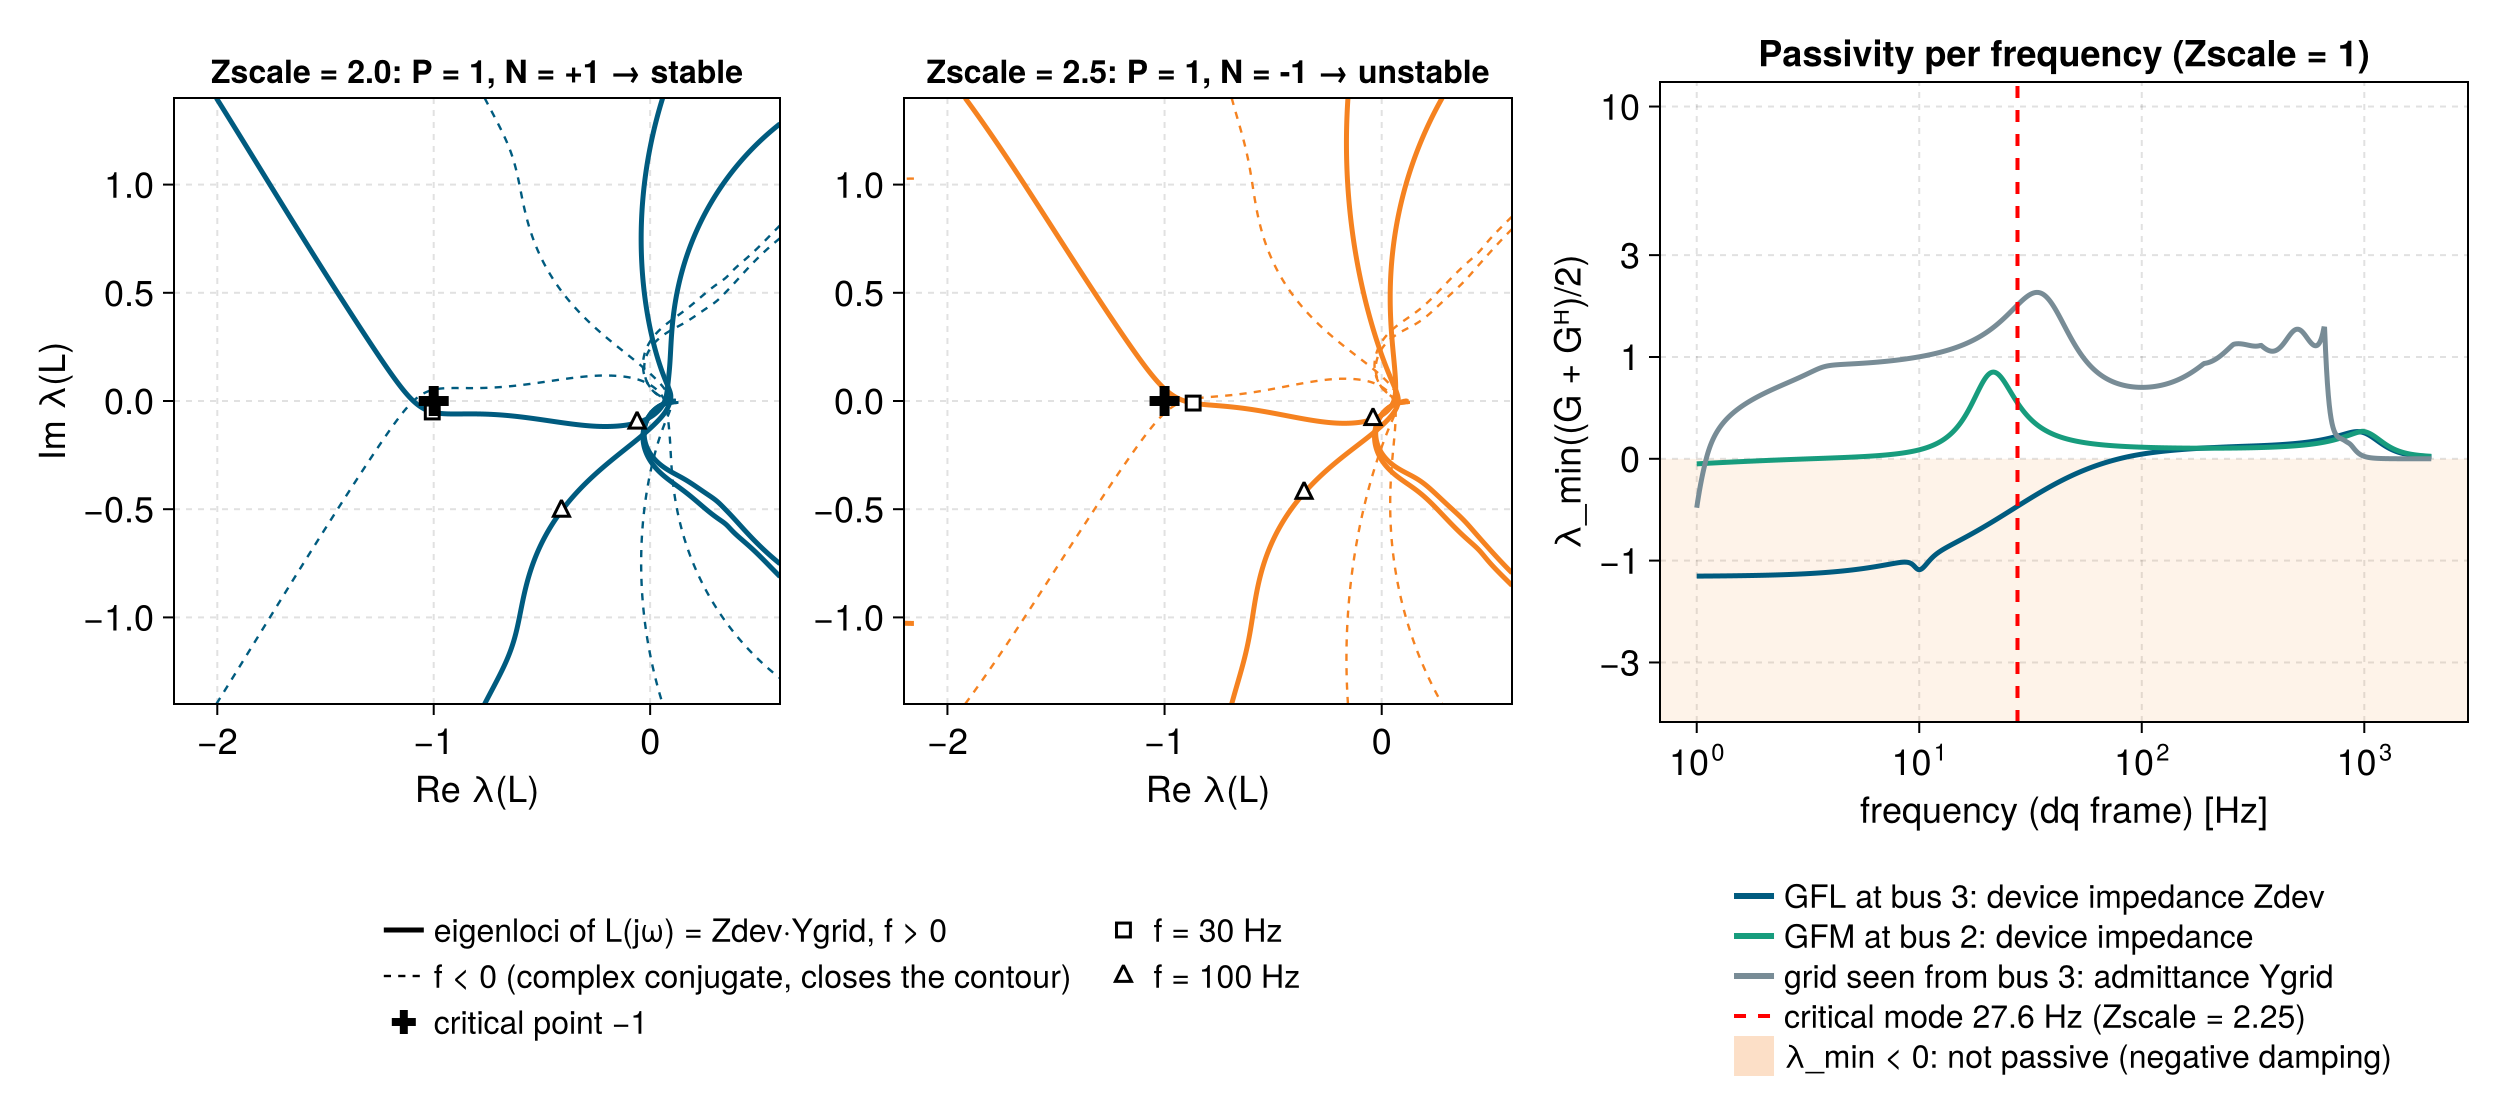

In [20]:
"eigenloci of L(jω) (2 branches, continuous ordering)"
function eigenloci(L, ωs)
    R = freqresp(L, ωs); loci = zeros(ComplexF64, 2, length(ωs))
    for k in eachindex(ωs)
        e = eigvals(R[:, :, k])
        if k > 1 && abs(e[1] - loci[2, k-1]) + abs(e[2] - loci[1, k-1]) < abs(e[1] - loci[1, k-1]) + abs(e[2] - loci[2, k-1])
            e = e[[2, 1]]
        end
        loci[:, k] = e
    end
    loci
end
let fig = Figure(size=(1250, 560))
    ωs = 2π .* 10 .^ range(-1, 4; length=20000)
    XL, YL = (-2.2, 0.6), (-1.4, 1.4)
    fmarks = [(10.0, :circle), (30.0, :rect), (100.0, :utriangle)]   # frequency markers on the f > 0 branches
    shown = Set{Float64}()
    for (col, Z) in enumerate((2.0, 2.5))
        c = cut_at_bus(op(Z), 3)
        L = c.Zdev * c.Ygrid
        g = gnc(L)
        clr = g.Zcl == 0 ? BLUE : ORANGE
        ax = Axis(fig[1, col]; aspect=DataAspect(), xlabel="Re λ(L)", ylabel=col == 1 ? "Im λ(L)" : "", titlesize=16,
            title=@sprintf("Zscale = %.1f: P = %d, N = %+d → %s", Z, g.P, g.N, g.Zcl == 0 ? "stable" : "unstable"))
        loci = eigenloci(L, ωs)
        for b in 1:2
            lines!(ax, real.(loci[b, :]), imag.(loci[b, :]); color=clr, linewidth=2.5)
            lines!(ax, real.(loci[b, :]), -imag.(loci[b, :]); color=clr, linewidth=1.2, linestyle=:dash)
        end
        for (f, mk) in fmarks
            pts = filter(λ -> XL[1] < real(λ) < XL[2] && YL[1] < imag(λ) < YL[2], eigenloci(L, [2π * f])[:, 1])
            isempty(pts) && continue
            push!(shown, f)
            scatter!(ax, real.(pts), imag.(pts); marker=mk, color=:white, strokecolor=:black, strokewidth=1.5, markersize=11)
        end
        scatter!(ax, [-1], [0]; color=:black, marker=:cross, markersize=20)
        xlims!(ax, XL...); ylims!(ax, YL...)
    end
    nyq_elems = Any[LineElement(color=:black, linewidth=2.5), LineElement(color=:black, linewidth=1.2, linestyle=:dash),
        MarkerElement(marker=:cross, color=:black, markersize=16)]
    nyq_labels = ["eigenloci of L(jω) = Zdev·Ygrid, f > 0", "f < 0 (complex conjugate, closes the contour)", "critical point −1"]
    for (f, mk) in fmarks
        f in shown || continue
        push!(nyq_elems, MarkerElement(marker=mk, color=:white, strokecolor=:black, strokewidth=1.5, markersize=11))
        push!(nyq_labels, @sprintf("f = %g Hz", f))
    end
    Legend(fig[2, 1:2], nyq_elems, nyq_labels; orientation=:horizontal, nbanks=3, framevisible=false, labelsize=16,
        tellheight=true)
    ax3 = Axis(fig[1, 3]; xscale=log10, yscale=Makie.pseudolog10, xlabel="frequency (dq frame) [Hz]",
        ylabel="λ_min((G + Gᴴ)/2)", title="Passivity per frequency (Zscale = 1)",
        yticks=([-3, -1, 0, 1, 3, 10], ["−3", "−1", "0", "1", "3", "10"]))
    hspan!(ax3, -100, 0; color=(ORANGE, 0.10))
    lines!(ax3, fs_pas, pas.gfl; color=BLUE)
    lines!(ax3, fs_pas, pas.gfm; color=GREEN)
    lines!(ax3, fs_pas, pas.grid; color=GREY)
    vlines!(ax3, imag(hz(λ_c1)); color=:red, linestyle=:dash, linewidth=2)
    ylims!(ax3, -5, 12)
    Legend(fig[2, 3],
        [LineElement(color=BLUE, linewidth=3), LineElement(color=GREEN, linewidth=3), LineElement(color=GREY, linewidth=3),
         LineElement(color=:red, linestyle=:dash, linewidth=2), PolyElement(color=(ORANGE, 0.25))],
        ["GFL at bus 3: device impedance Zdev", "GFM at bus 2: device impedance",
         "grid seen from bus 3: admittance Ygrid", @sprintf("critical mode %.1f Hz (Zscale = %.2f)", imag(hz(λ_c1)), Z_NEAR),
         "λ_min < 0: not passive (negative damping)"];
        framevisible=false, labelsize=16, rowgap=0, tellheight=true)
    colsize!(fig.layout, 3, Relative(0.4))
    exportfig("nyquist_passivity", fig)
end

## 8 Gradient-based tuning in the time domain

Following the PoSyDyS companion: seven GFL controller gains are tuned to minimize the voltage oscillation energy after
the load step, evaluated at three grid strengths at once. The gradient of this loss is computed by **forward-mode AD
through the stiff ODE solver** (`Rodas5P(autodiff=AutoForwardDiff())`), and Adam (Optimization.jl / Optimisers.jl)
updates the gains.

In [21]:
tunable = collect(VIndex(3, [:gfl₊csrc₊PLL_Kp, :gfl₊csrc₊PLL_Ki, :gfl₊csrc₊CC1_KI, :gfl₊csrc₊CC1_KP,
    :gfl₊csrc₊CC2_F, :gfl₊csrc₊CC2_KP, :gfl₊csrc₊CC2_KI]))
const TPIDX = SII.parameter_index(nw, tunable)
const P0 = pflat(s0)[TPIDX]
opt_scales = [1.0, 1.5, 2.0]
opt_probs = [load_step_problem(op(Z); tspan=(-10.0, 1.0)) for Z in opt_scales]
const T_EVAL = range(0.0, 1.0; length=1000)
function td_loss(p)
    total = zero(eltype(p))
    for prob in opt_probs
        pn = zeros(eltype(p), length(prob.p)); pn .= prob.p; pn[TPIDX] .= p
        sol = solve(prob, Rodas5P(autodiff=AutoForwardDiff()); p=pn, saveat=T_EVAL)
        SciMLBase.successful_retcode(sol) || return oftype(total, Inf)
        V = reduce(hcat, sol(T_EVAL; idxs=VIndex([2, 3, 8], :busbar₊u_mag)).u)
        total += sum(abs2, V .- V[:, end]) / length(T_EVAL)
    end
    total
end
const TD_ITERS = parse(Int, get(ENV, "TUTORIAL_TD_ITERS", "100"))
td_hist = Float64[]
t_td = @elapsed td_sol = let
    optf = OptimizationFunction((x, _) -> td_loss(x), AutoForwardDiff())
    cb = (state, l) -> (push!(td_hist, l); false)
    solve(OptimizationProblem(optf, copy(P0); callback=cb), Optimisers.Adam(5e-3); maxiters=TD_ITERS)
end
p_td = td_sol.u
ForwardDiff.gradient(td_loss, p_td)                     # compile
t_td_grad = @elapsed ForwardDiff.gradient(td_loss, p_td)
@printf("time-domain tuning: loss %.3e → %.3e in %d iterations (%.0f s, %.2f s per gradient)\n",
    td_hist[1], minimum(td_hist), length(td_hist), t_td, t_td_grad)

┌ Warning: The supplied DiffCache was too small and was enlarged. This incurs allocations
│         on the first call to `get_tmp`. If few calls to `get_tmp` occur and optimal performance is essential,
│         consider changing 'N'/chunk size of this DiffCache to 15.
└ @ PreallocationTools ~/.julia\packages\PreallocationTools\dNQ2d\src\PreallocationTools.jl:566
time-domain tuning: loss 3.154e-05 → 1.462e-05 in 101 iterations (102 s, 0.68 s per gradient)


Re-initialize the system with tuned gains (integral gains and the feed-forward gain change the controller states at
the equilibrium).

In [22]:
function retuned_state(pvals)
    nwt = Network(nw)
    for (sym, v) in zip(tunable, pvals)
        set_default!(nwt[VIndex(sym.compidx)], sym.subidx, v)
    end
    initialize_from_pf!(nwt; tol=1e-7, nwtol=1e-5, verbose=false, warn=false)
end
tuned_ops(pvals) = (st = retuned_state(pvals); Z -> last(rebuild_with_scale(st, Z)))
min_damping(s) = minimum(ζ(λ) for λ in eigvals(Aₛ(s)) if inband(λ))
"grid strength at which the least-damped converter mode crosses ζ = 0 (bisection on Zscale)"
function zcrit(pvals; lo=1.0, hi=4.0)
    opt = tuned_ops(pvals)
    f(Z) = min_damping(opt(Z))
    f(hi) > 0 && return Inf
    for _ in 1:25
        mid = (lo + hi) / 2
        f(mid) > 0 ? (lo = mid) : (hi = mid)
    end
    (lo + hi) / 2
end

Main.var"##277".zcrit

## 9 Modal gradient-based tuning

The same seven gains, now tuned with a **modal objective**: penalize converter modes (5–150 Hz) with damping ratio
below $\zeta_\text{min}$ at three grid strengths. The gradient follows from eigenvalue sensitivities
$\partial\lambda/\partial p = \mathbf w^\top(\partial\mathbf A_s/\partial p)\mathbf v$ with nested AD — no time-domain
simulation in the loop. Parameters are optimized in log space, $p = p_0 e^\theta$. Each iteration re-initializes the
system with the current gains, but the sensitivities are taken at that frozen operating point: they neglect that
integral gains and the feed-forward gain move the controller states, so the gradient is approximate for those gains.
Adam converges nevertheless; exact gradients would require differentiating through the re-initialization.

In [23]:
const ZETA_MIN = 0.10
modal_scales = [1.0, 2.0, 2.5]
softplus(x) = x > 30 ? x : log1p(exp(x))
sigmoid(x) = 1 / (1 + exp(-x))
const SOFT = 0.01
penalty(d) = (SOFT * softplus(d / SOFT))^2
dpenalty(d) = 2 * SOFT * softplus(d / SOFT) * sigmoid(d / SOFT)
"∂Aₛ/∂p_k at the (frozen) operating point of s by nested forward-mode AD"
function dAs_dp(s, k)
    nws = extract_nw(s)
    ForwardDiff.derivative(0.0) do δ
        p = Vector{typeof(δ)}(pflat(s)); p[k] += δ
        J = ForwardDiff.jacobian(x -> (du = zeros(promote_type(eltype(x), typeof(δ)), length(x)); nws(du, x, p, s.t); du), uflat(s))
        reduce_dae(NetworkDescriptorSystem(; M=nws.mass_matrix, A=J)).A
    end
end
function modal_objective_and_gradient(θ)
    pvals = P0 .* exp.(θ)
    st = retuned_state(pvals)
    J = 0.0; g = zeros(length(θ))
    for Z in modal_scales
        s = last(rebuild_with_scale(st, Z))
        E = eigen(Aₛ(s)); W = inv(E.vectors)
        modes = [i for i in eachindex(E.values) if inband(E.values[i]) && ζ(E.values[i]) < ZETA_MIN + 5SOFT]
        J += sum(penalty(ZETA_MIN - ζ(E.values[i])) for i in eachindex(E.values) if inband(E.values[i]); init=0.0)
        isempty(modes) && continue
        for (k, pk) in enumerate(TPIDX)
            dA = dAs_dp(s, pk) .* pvals[k]                     # ∂Aₛ/∂θ_k
            for i in modes
                λ = E.values[i]; dλ = transpose(W[i, :]) * (dA * E.vectors[:, i])
                σ, ω = reim(λ); r = abs(λ)
                dζ = (-ω^2 / r^3) * real(dλ) + (σ * ω / r^3) * imag(dλ)
                g[k] += dpenalty(ZETA_MIN - ζ(λ)) * (-dζ)
            end
        end
    end
    J, g
end
function adam!(θ, f; iters=40, lr=0.05, β1=0.9, β2=0.999, ϵ=1e-8, θmax=log(10.0))
    m = zero(θ); v = zero(θ); hist = Float64[]
    for it in 1:iters
        J, g = f(θ); push!(hist, J)
        J < 1e-10 && break
        m .= β1 .* m .+ (1 - β1) .* g; v .= β2 .* v .+ (1 - β2) .* g .^ 2
        θ .-= lr .* (m ./ (1 - β1^it)) ./ (sqrt.(v ./ (1 - β2^it)) .+ ϵ)
        clamp!(θ, -θmax, θmax)
    end
    hist
end
θ = zeros(length(TPIDX))
t_modal = @elapsed modal_hist = adam!(θ, modal_objective_and_gradient)
p_modal = P0 .* exp.(θ)
t_modal_grad = @elapsed modal_objective_and_gradient(θ)
@printf("modal tuning: objective %.3e → %.3e in %d iterations (%.0f s, %.2f s per gradient incl. re-initialization)\n",
    modal_hist[1], modal_hist[end], length(modal_hist), t_modal, t_modal_grad)

┌ Warning: The supplied DiffCache was too small and was enlarged. This incurs allocations
│         on the first call to `get_tmp`. If few calls to `get_tmp` occur and optimal performance is essential,
│         consider changing 'N'/chunk size of this DiffCache to 23.
└ @ PreallocationTools ~/.julia\packages\PreallocationTools\dNQ2d\src\PreallocationTools.jl:566
modal tuning: objective 2.144e-02 → 3.003e-10 in 40 iterations (19 s, 0.33 s per gradient incl. re-initialization)


### Comparison of both tunings

stability limit Zscale*: (default = 2.2634862512350082, td = Inf, modal = Inf)
parameter        default      time-domain   modal
PLL_Kp                  250        250.1        218.8
PLL_Ki                 1000         1000        550.6
CC1_KI                   63        63.15        56.03
CC1_KP                0.063       0.1977       0.1123
CC2_F                     1       0.7617       0.5502
CC2_KP                0.189       0.2306        0.122
CC2_KI                 0.63        0.149       0.3301


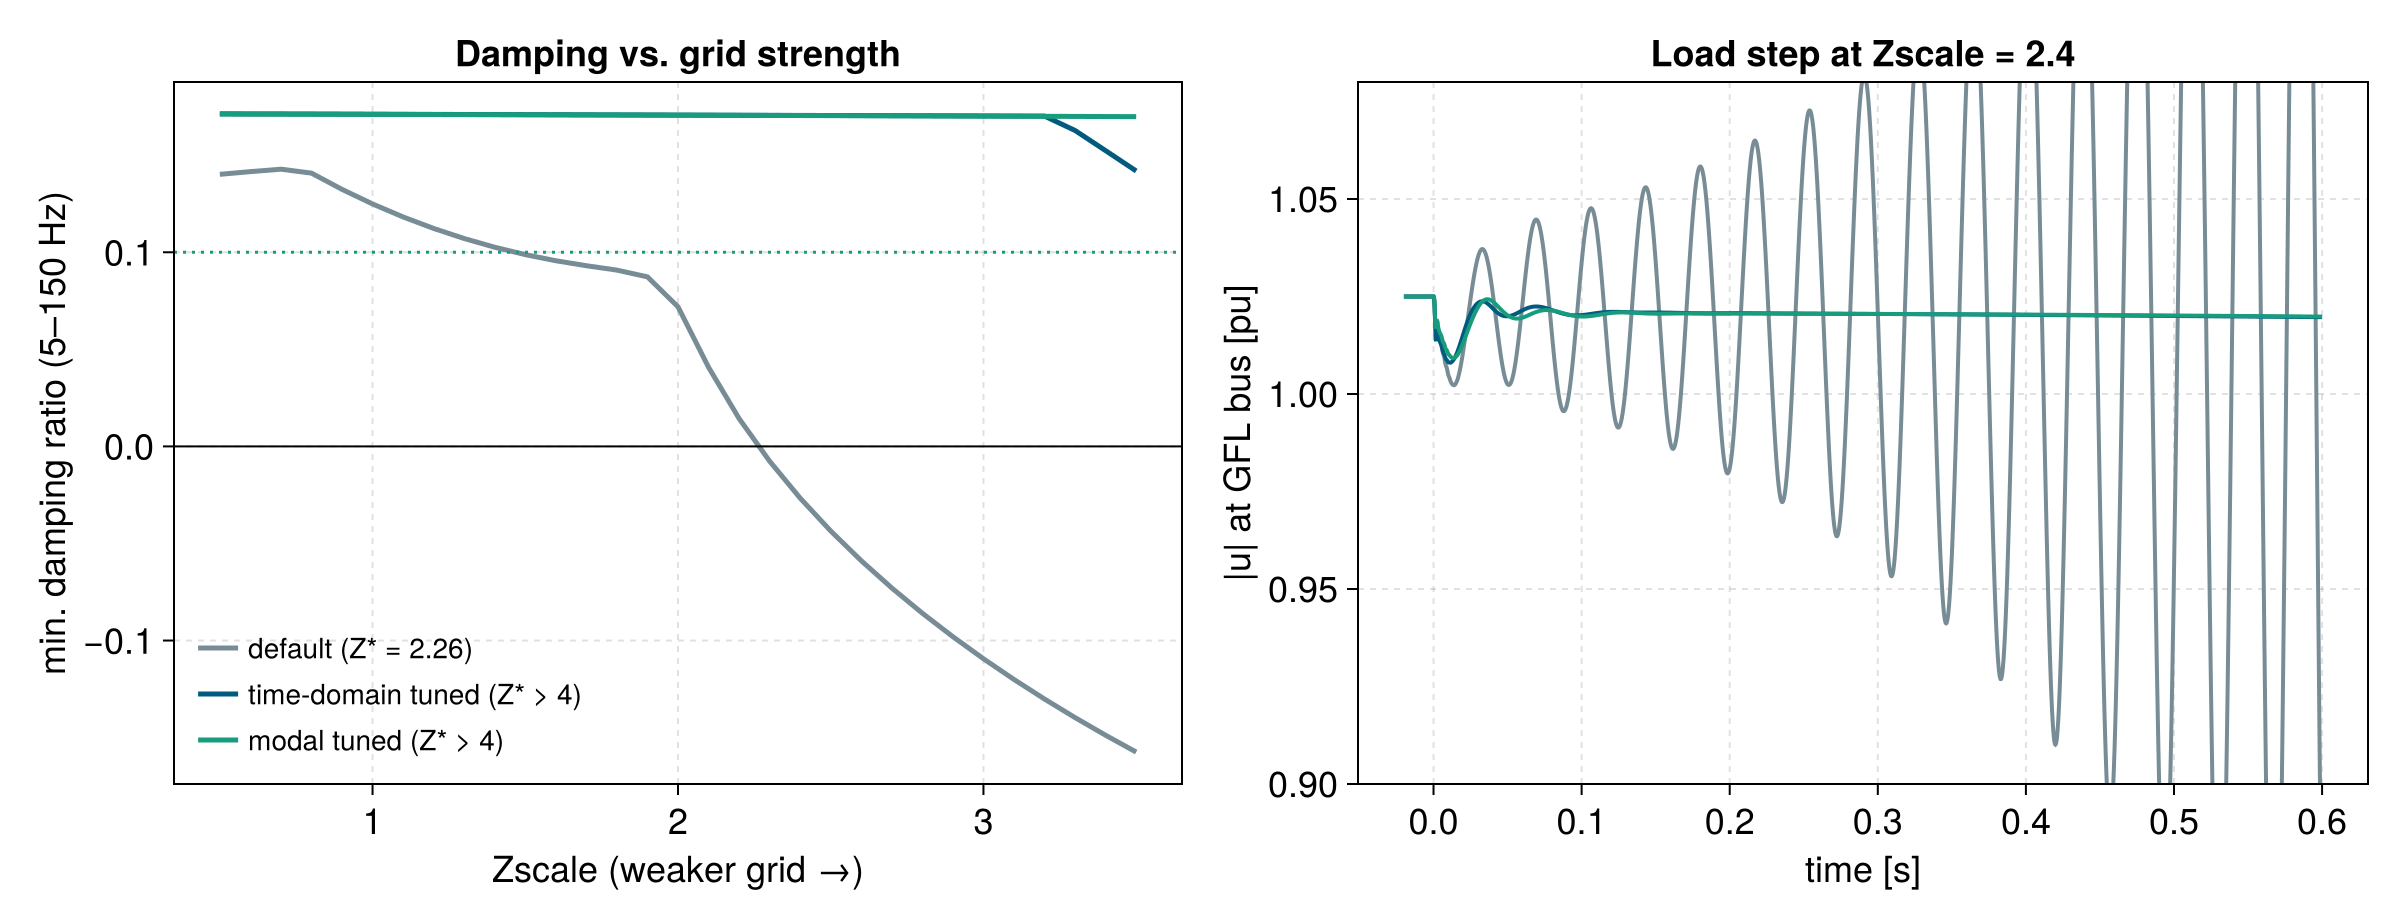

In [24]:
zstars = (; default = zcrit(P0), td = zcrit(p_td), modal = zcrit(p_modal))
println("stability limit Zscale*: ", zstars)
println("parameter        default      time-domain   modal")
for (sym, a, b, c) in zip(tunable, P0, p_td, p_modal)
    @printf("%-16s %10.4g %12.4g %12.4g\n", replace(string(sym.subidx), "gfl₊csrc₊" => ""), a, b, c)
end

Zcmp = collect(0.5:0.1:3.5)
ops_td, ops_modal = tuned_ops(p_td), tuned_ops(p_modal)
damp = (; default = [min_damping(op(Z)) for Z in Zcmp],
          td = [min_damping(ops_td(Z)) for Z in Zcmp],
          modal = [min_damping(ops_modal(Z)) for Z in Zcmp])
Z_show = 2.4
sols_cmp = (; default = solve(load_step_problem(op(Z_show)), Rodas5P()),
              td = solve(load_step_problem(ops_td(Z_show)), Rodas5P()),
              modal = solve(load_step_problem(ops_modal(Z_show)), Rodas5P()))

let fig = Figure(size=(1200, 460))
    ax1 = Axis(fig[1, 1]; xlabel="Zscale (weaker grid →)", ylabel="min. damping ratio (5–150 Hz)", title="Damping vs. grid strength")
    lines!(ax1, Zcmp, damp.default; color=GREY, label=@sprintf("default (Z* = %.2f)", zstars.default))
    zlab(z) = isinf(z) ? "Z* > 4" : @sprintf("Z* = %.2f", z)
    lines!(ax1, Zcmp, damp.td; color=BLUE, label="time-domain tuned ($(zlab(zstars.td)))")
    lines!(ax1, Zcmp, damp.modal; color=GREEN, label="modal tuned ($(zlab(zstars.modal)))")
    hlines!(ax1, 0; color=:black, linewidth=1); hlines!(ax1, ZETA_MIN; color=GREEN, linestyle=:dot, linewidth=1.5)
    axislegend(ax1; position=:lb, framevisible=false, labelsize=14)
    ax2 = Axis(fig[1, 2]; xlabel="time [s]", ylabel="|u| at GFL bus [pu]", title="Load step at Zscale = $Z_show")
    ts = range(-0.02, 0.6; length=3000)
    for (sol, c, lab) in ((sols_cmp.default, GREY, "default"), (sols_cmp.td, BLUE, "time-domain tuned"), (sols_cmp.modal, GREEN, "modal tuned"))
        lines!(ax2, ts, sol(ts; idxs=VIndex(3, :busbar₊u_mag)).u; color=c, label=lab, linewidth=2)
    end
    ylims!(ax2, 0.9, 1.08)
    exportfig("tuning_comparison", fig)
end

## 10 Summary

| Question | Result in this tutorial | Building block |
|---|---|---|
| Which modes are critical, which devices take part? | 43.6 Hz GFM–GFL mode; ≈ 77 % participation of the two inverters (GFL 47 %, GFM 30 %) | `linearize_network`, `participation_factors` (ForwardDiff) |
| Which parameters matter? | ranking changes with grid strength | `eigenvalue_sensitivity` (nested ForwardDiff) |
| When does the system become unstable? | Hopf crossing located exactly; nearest-neighbour matching can lose the mode | BifurcationKit.jl, KrylovKit.jl |
| Which parameter combinations are stable? | stability boundary grid strength × PLL bandwidth | BifurcationKit.jl (PALC) |
| Impedance-based / frequency-domain view | exact dq impedances, generalized Nyquist ≡ modal | `open_loop_linearization`, ControlSystemsBase.jl |
| Passivity | GFL non-passive below ≈ 100 Hz (incl. the critical mode), grid passive above ≈ 1 Hz | RobustAndOptimalControl.jl |
| How to tune? | gradients through the ODE solver or from eigenvalue sensitivities | Optimization.jl, OrdinaryDiffEq.jl, ForwardDiff.jl |

All of these analyses use the same nonlinear model and the same AD machinery, so they apply unchanged to
user-defined component models.